<a href="https://colab.research.google.com/github/Alvisha-28/Grid-Energy-Analytics-Daily-Electricity-Demand-Supply-and-Peak-Shortage-Forecasting-using-ML/blob/main/national__grid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# 2. UPLOAD DATASETS
# ============================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving india_power_synthetic_2000.csv to india_power_synthetic_2000.csv
Saving india_power_overall_synthetic_2000.csv to india_power_overall_synthetic_2000.csv
Saving india_power_regional_synthetic_2000.csv to india_power_regional_synthetic_2000.csv

Uploaded files:
india_power_synthetic_2000.csv
india_power_overall_synthetic_2000.csv
india_power_regional_synthetic_2000.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

warnings.filterwarnings('ignore')

regional_df = pd.read_csv(
    "india_power_regional_synthetic_2000.csv"
)

overall_df = pd.read_csv(
    "india_power_overall_synthetic_2000.csv"
)

synthetic_df = pd.read_csv(
    "india_power_synthetic_2000.csv"
)

print("All three synthetic datasets loaded!")


All three synthetic datasets loaded!


In [ ]:

datasets = {
    "Regional Synthetic": regional_df,
    "All India Synthetic": overall_df,
    "ML Synthetic": synthetic_df
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    display(df.head())



Regional Synthetic
Shape: (2000, 28)


,Date,Region,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Season,Latitude,...,Nuclear_Actual_MU,Nuclear_Estimated_MU,Hydro_Actual_MU,Hydro_Estimated_MU,Total_Actual_MU,Total_Estimated_MU,Estimation_Error_MU,Thermal_Share_Pct,Nuclear_Share_Pct,Hydro_Share_Pct
0,2024-01-01,Northern,synthetic,2024,1,1,0,0,Winter,29.5,...,42.121248,42.443877,156.747859,155.145635,791.935942,805.556494,13.620552,74.888233,5.318770,19.792997
1,2024-01-02,Northern,synthetic,2024,1,2,1,0,Winter,29.5,...,42.158934,42.523221,172.557238,175.665802,827.044928,828.027830,0.982902,74.038149,5.097539,20.864312
2,2024-01-03,Northern,synthetic,2024,1,3,2,0,Winter,29.5,...,41.968466,41.765128,176.822102,180.215160,839.110380,835.444121,-3.666259,73.925890,5.001543,21.072568
3,2024-01-04,Northern,synthetic,2024,1,4,3,0,Winter,29.5,...,41.324336,41.209149,170.801756,169.912622,825.576708,831.822876,6.246168,74.305708,5.005511,20.688781
4,2024-01-05,Northern,synthetic,2024,1,5,4,0,Winter,29.5,...,42.943211,42.309363,168.655769,169.688654,832.445110,847.910668,15.465558,74.581029,5.158684,20.260287



All India Synthetic
Shape: (2000, 28)


,Date,Region,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Season,Latitude,...,Nuclear_Actual_MU,Nuclear_Estimated_MU,Hydro_Actual_MU,Hydro_Estimated_MU,Total_Actual_MU,Total_Estimated_MU,Estimation_Error_MU,Thermal_Share_Pct,Nuclear_Share_Pct,Hydro_Share_Pct
0,2021-01-01,All India,synthetic,2021,1,1,4,0,Winter,22.907599,...,128.250482,130.075260,572.040052,570.800476,3801.045290,3759.858490,-41.186800,81.576370,3.374085,15.049546
1,2021-01-02,All India,synthetic,2021,1,2,5,1,Winter,22.907599,...,127.022930,127.393555,563.329731,563.112141,3912.827862,3949.714901,36.887039,82.356682,3.246320,14.396998
2,2021-01-03,All India,synthetic,2021,1,3,6,1,Winter,22.907599,...,128.582145,126.694600,548.131198,547.322254,3866.716945,3918.540632,51.823687,82.499020,3.325357,14.175623
3,2021-01-04,All India,synthetic,2021,1,4,0,0,Winter,22.907599,...,127.696566,128.712595,608.107406,603.294572,3881.273150,3880.649142,-0.624008,81.042201,3.290069,15.667730
4,2021-01-05,All India,synthetic,2021,1,5,1,0,Winter,22.907599,...,127.156126,126.887747,584.038435,592.253491,3864.112595,3843.103215,-21.009380,81.594880,3.290694,15.114426



ML Synthetic
Shape: (2000, 28)


,Date,Region,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Season,Latitude,...,Nuclear_Actual_MU,Nuclear_Estimated_MU,Hydro_Actual_MU,Hydro_Estimated_MU,Total_Actual_MU,Total_Estimated_MU,Estimation_Error_MU,Thermal_Share_Pct,Nuclear_Share_Pct,Hydro_Share_Pct
0,2024-01-01,Northern,synthetic,2024,1,1,0,0,Winter,29.5,...,41.452861,41.206269,170.756283,162.227299,872.031810,885.611714,13.579904,75.664977,4.753595,19.581428
1,2024-01-02,Northern,synthetic,2024,1,2,1,0,Winter,29.5,...,42.358169,41.735724,201.894786,205.593202,863.050084,861.644092,-1.405993,71.698867,4.907962,23.393171
2,2024-01-03,Northern,synthetic,2024,1,3,2,0,Winter,29.5,...,42.588370,42.444814,183.125883,178.970158,850.891523,833.570640,-17.320883,73.473205,5.005147,21.521649
3,2024-01-04,Northern,synthetic,2024,1,4,3,0,Winter,29.5,...,42.553839,42.099146,189.064808,206.093184,862.491702,867.932966,5.441264,73.145406,4.933826,21.920768
4,2024-01-05,Northern,synthetic,2024,1,5,4,0,Winter,29.5,...,42.019566,42.265669,162.887366,160.623523,823.993703,840.261833,16.268131,75.132464,5.099501,19.768035


In [ ]:

# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# ============================================
# TAB 2: DATASET INSPECTION
# STEP 1: COLUMN NAMES AND DATA TYPES
# ============================================

datasets = {
    "Regional Synthetic": regional_df,
    "All India Synthetic": overall_df,
    "ML Synthetic": synthetic_df
}

for name, df in datasets.items():

    print("\n" + "="*65)
    print("DATASET:", name)
    print("="*65)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    display(df.dtypes.to_frame(name="Data Type"))

    print("\nDataset Information:")
    df.info()



DATASET: Regional Synthetic

Column Names:
['Date', 'Region', 'Data_Source', 'Year', 'Month', 'Day', 'DayOfWeek', 'Is_Weekend', 'Season', 'Latitude', 'Longitude', 'Centroid_Lat', 'Centroid_Lon', 'Num_States_UTs', 'Area_km2', 'National_Share_pct', 'Thermal_Actual_MU', 'Thermal_Estimated_MU', 'Nuclear_Actual_MU', 'Nuclear_Estimated_MU', 'Hydro_Actual_MU', 'Hydro_Estimated_MU', 'Total_Actual_MU', 'Total_Estimated_MU', 'Estimation_Error_MU', 'Thermal_Share_Pct', 'Nuclear_Share_Pct', 'Hydro_Share_Pct']

Data Types:


,Data Type
Date,object
Region,object
Data_Source,object
Year,int64
Month,int64
Day,int64
DayOfWeek,int64
Is_Weekend,int64
Season,object
Latitude,float64



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  2000 non-null   object 
 1   Region                2000 non-null   object 
 2   Data_Source           2000 non-null   object 
 3   Year                  2000 non-null   int64  
 4   Month                 2000 non-null   int64  
 5   Day                   2000 non-null   int64  
 6   DayOfWeek             2000 non-null   int64  
 7   Is_Weekend            2000 non-null   int64  
 8   Season                2000 non-null   object 
 9   Latitude              2000 non-null   float64
 10  Longitude             2000 non-null   float64
 11  Centroid_Lat          2000 non-null   float64
 12  Centroid_Lon          2000 non-null   float64
 13  Num_States_UTs        2000 non-null   int64  
 14  Area_km2              2000 non-null   int64  
 15 

,Data Type
Date,object
Region,object
Data_Source,object
Year,int64
Month,int64
Day,int64
DayOfWeek,int64
Is_Weekend,int64
Season,object
Latitude,float64



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  2000 non-null   object 
 1   Region                2000 non-null   object 
 2   Data_Source           2000 non-null   object 
 3   Year                  2000 non-null   int64  
 4   Month                 2000 non-null   int64  
 5   Day                   2000 non-null   int64  
 6   DayOfWeek             2000 non-null   int64  
 7   Is_Weekend            2000 non-null   int64  
 8   Season                2000 non-null   object 
 9   Latitude              2000 non-null   float64
 10  Longitude             2000 non-null   float64
 11  Centroid_Lat          2000 non-null   float64
 12  Centroid_Lon          2000 non-null   float64
 13  Num_States_UTs        2000 non-null   int64  
 14  Area_km2              2000 non-null   int64  
 15 

,Data Type
Date,object
Region,object
Data_Source,object
Year,int64
Month,int64
Day,int64
DayOfWeek,int64
Is_Weekend,int64
Season,object
Latitude,float64



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  2000 non-null   object 
 1   Region                2000 non-null   object 
 2   Data_Source           2000 non-null   object 
 3   Year                  2000 non-null   int64  
 4   Month                 2000 non-null   int64  
 5   Day                   2000 non-null   int64  
 6   DayOfWeek             2000 non-null   int64  
 7   Is_Weekend            2000 non-null   int64  
 8   Season                2000 non-null   object 
 9   Latitude              2000 non-null   float64
 10  Longitude             2000 non-null   float64
 11  Centroid_Lat          2000 non-null   float64
 12  Centroid_Lon          2000 non-null   float64
 13  Num_States_UTs        2000 non-null   int64  
 14  Area_km2              2000 non-null   int64  
 15 

In [ ]:

# ============================================
# STEP 2: MISSING VALUE ANALYSIS
# ============================================

for name, df in datasets.items():

    print("\n", "="*55)
    print("MISSING VALUES:", name)
    print("="*55)

    missing = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().sum() / len(df)
        ) * 100
    })

    display(missing.round(2))

    print(
        "Total missing values:",
        df.isnull().sum().sum()
    )



MISSING VALUES: Regional Synthetic


,Missing_Count,Missing_Percentage
Date,0,0.0
Region,0,0.0
Data_Source,0,0.0
Year,0,0.0
Month,0,0.0
Day,0,0.0
DayOfWeek,0,0.0
Is_Weekend,0,0.0
Season,0,0.0
Latitude,0,0.0


Total missing values: 0

MISSING VALUES: All India Synthetic


,Missing_Count,Missing_Percentage
Date,0,0.0
Region,0,0.0
Data_Source,0,0.0
Year,0,0.0
Month,0,0.0
Day,0,0.0
DayOfWeek,0,0.0
Is_Weekend,0,0.0
Season,0,0.0
Latitude,0,0.0


Total missing values: 0

MISSING VALUES: ML Synthetic


,Missing_Count,Missing_Percentage
Date,0,0.0
Region,0,0.0
Data_Source,0,0.0
Year,0,0.0
Month,0,0.0
Day,0,0.0
DayOfWeek,0,0.0
Is_Weekend,0,0.0
Season,0,0.0
Latitude,0,0.0


Total missing values: 0


In [ ]:

# ============================================
# STEP 3: DUPLICATE RECORD ANALYSIS
# ============================================

for name, df in datasets.items():

    print("\nDataset:", name)

    print(
        "Total duplicate rows:",
        df.duplicated().sum()
    )

    print(
        "Duplicate Date-Region combinations:",
        df.duplicated(
            subset=["Date", "Region"]
        ).sum()
    )



Dataset: Regional Synthetic
Total duplicate rows: 0
Duplicate Date-Region combinations: 0

Dataset: All India Synthetic
Total duplicate rows: 0
Duplicate Date-Region combinations: 0

Dataset: ML Synthetic
Total duplicate rows: 0
Duplicate Date-Region combinations: 0


In [ ]:

# ============================================
# STEP 4: DATE VALIDATION
# ============================================

for name, df in datasets.items():

    print("\nDataset:", name)

    # Convert Date into datetime format
    df["Date"] = pd.to_datetime(
        df["Date"],
        errors="coerce"
    )

    print("Starting Date:", df["Date"].min())
    print("Ending Date:", df["Date"].max())

    print(
        "Invalid Dates:",
        df["Date"].isnull().sum()
    )

    print(
        "Number of Unique Dates:",
        df["Date"].nunique()
    )



Dataset: Regional Synthetic
Starting Date: 2024-01-01 00:00:00
Ending Date: 2025-02-03 00:00:00
Invalid Dates: 0
Number of Unique Dates: 400

Dataset: All India Synthetic
Starting Date: 2021-01-01 00:00:00
Ending Date: 2026-06-23 00:00:00
Invalid Dates: 0
Number of Unique Dates: 2000

Dataset: ML Synthetic
Starting Date: 2024-01-01 00:00:00
Ending Date: 2025-02-03 00:00:00
Invalid Dates: 0
Number of Unique Dates: 400


In [ ]:

# ============================================
# STEP 5: UNIQUE REGION ANALYSIS
# ============================================

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Unique Regions:")
    print(df["Region"].unique())

    print("\nRecords per Region:")
    display(
        df["Region"].value_counts().to_frame(
            name="Number_of_Records"
        )
    )



Dataset: Regional Synthetic
Unique Regions:
['Northern' 'Western' 'Southern' 'Eastern' 'NorthEastern']

Records per Region:


,Number_of_Records
Region,
Northern,400
Western,400
Southern,400
Eastern,400
NorthEastern,400



Dataset: All India Synthetic
Unique Regions:
['All India']

Records per Region:


,Number_of_Records
Region,
All India,2000



Dataset: ML Synthetic
Unique Regions:
['Northern' 'Western' 'Southern' 'Eastern' 'NorthEastern']

Records per Region:


,Number_of_Records
Region,
Northern,400
Western,400
Southern,400
Eastern,400
NorthEastern,400


In [ ]:

# ============================================
# STEP 6: ZERO VALUE ANALYSIS
# ============================================

generation_columns = [
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU",
    "Total_Actual_MU"
]

for name, df in datasets.items():

    print("\nDataset:", name)

    zero_summary = pd.DataFrame({
        "Zero_Count": (df[generation_columns] == 0).sum(),
        "Zero_Percentage": (
            (df[generation_columns] == 0).sum()
            / len(df)
        ) * 100
    })

    display(zero_summary.round(2))



Dataset: Regional Synthetic


,Zero_Count,Zero_Percentage
Thermal_Actual_MU,0,0.0
Nuclear_Actual_MU,800,40.0
Hydro_Actual_MU,0,0.0
Total_Actual_MU,0,0.0



Dataset: All India Synthetic


,Zero_Count,Zero_Percentage
Thermal_Actual_MU,0,0.0
Nuclear_Actual_MU,0,0.0
Hydro_Actual_MU,0,0.0
Total_Actual_MU,0,0.0



Dataset: ML Synthetic


,Zero_Count,Zero_Percentage
Thermal_Actual_MU,0,0.0
Nuclear_Actual_MU,800,40.0
Hydro_Actual_MU,0,0.0
Total_Actual_MU,0,0.0


In [ ]:

# ============================================
# STEP 7: VERIFY GENERATION TOTALS
# ============================================

for name, df in datasets.items():

    calculated_total = (
        df["Thermal_Actual_MU"]
        + df["Nuclear_Actual_MU"]
        + df["Hydro_Actual_MU"]
    )

    difference = (
        df["Total_Actual_MU"] - calculated_total
    )

    print("\nDataset:", name)

    print(
        "Maximum absolute difference:",
        difference.abs().max()
    )

    print(
        "Incorrect total records:",
        (difference.abs() > 0.001).sum()
    )



Dataset: Regional Synthetic
Maximum absolute difference: 4.547473508864641e-13
Incorrect total records: 0

Dataset: All India Synthetic
Maximum absolute difference: 1.8189894035458565e-12
Incorrect total records: 0

Dataset: ML Synthetic
Maximum absolute difference: 4.547473508864641e-13
Incorrect total records: 0


In [ ]:

# ============================================
# STEP 8: VERIFY ESTIMATION ERROR
# ============================================

for name, df in datasets.items():

    calculated_error = (
        df["Total_Estimated_MU"]
        - df["Total_Actual_MU"]
    )

    difference = (
        df["Estimation_Error_MU"]
        - calculated_error
    )

    print("\nDataset:", name)

    print(
        "Maximum error difference:",
        difference.abs().max()
    )

    print(
        "Incorrect records:",
        (difference.abs() > 0.001).sum()
    )



Dataset: Regional Synthetic
Maximum error difference: 4.583000645652646e-13
Incorrect records: 0

Dataset: All India Synthetic
Maximum error difference: 2.1600499167107046e-12
Incorrect records: 0

Dataset: ML Synthetic
Maximum error difference: 4.583000645652646e-13
Incorrect records: 0


In [ ]:

# ============================================
# STEP 9: VERIFY GENERATION SHARES
# ============================================

for name, df in datasets.items():

    total = df["Total_Actual_MU"].replace(0, np.nan)

    thermal_share = (
        df["Thermal_Actual_MU"] / total
    ) * 100

    nuclear_share = (
        df["Nuclear_Actual_MU"] / total
    ) * 100

    hydro_share = (
        df["Hydro_Actual_MU"] / total
    ) * 100

    print("\nDataset:", name)

    print(
        "Thermal share maximum difference:",
        (df["Thermal_Share_Pct"] - thermal_share).abs().max()
    )

    print(
        "Nuclear share maximum difference:",
        (df["Nuclear_Share_Pct"] - nuclear_share).abs().max()
    )

    print(
        "Hydro share maximum difference:",
        (df["Hydro_Share_Pct"] - hydro_share).abs().max()
    )



Dataset: Regional Synthetic
Thermal share maximum difference: 4.263256414560601e-14
Nuclear share maximum difference: 2.6645352591003757e-15
Hydro share maximum difference: 1.4210854715202004e-14

Dataset: All India Synthetic
Thermal share maximum difference: 4.263256414560601e-14
Nuclear share maximum difference: 1.3322676295501878e-15
Hydro share maximum difference: 1.0658141036401503e-14

Dataset: ML Synthetic
Thermal share maximum difference: 5.684341886080802e-14
Nuclear share maximum difference: 1.7763568394002505e-15
Hydro share maximum difference: 1.4210854715202004e-14


In [ ]:

# ============================================
# STEP 10: OUTLIER DETECTION USING IQR
# ============================================

for name, df in datasets.items():

    print("\nDataset:", name)

    outlier_summary = []

    for col in generation_columns:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower) |
            (df[col] > upper)
        ]

        outlier_summary.append({
            "Column": col,
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": len(outliers)
        })

    display(pd.DataFrame(outlier_summary).round(3))



Dataset: Regional Synthetic


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Thermal_Actual_MU,5.090,1350.193,0
1,Nuclear_Actual_MU,-63.557,105.929,0
2,Hydro_Actual_MU,-135.910,365.012,0
3,Total_Actual_MU,-191.679,1840.147,0



Dataset: All India Synthetic


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Thermal_Actual_MU,2403.284,4080.264,0
1,Nuclear_Actual_MU,124.713,131.369,3
2,Hydro_Actual_MU,320.286,865.326,0
3,Total_Actual_MU,3335.911,4559.473,3



Dataset: ML Synthetic


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,Thermal_Actual_MU,12.790,1338.035,0
1,Nuclear_Actual_MU,-63.528,105.880,0
2,Hydro_Actual_MU,-134.933,363.680,0
3,Total_Actual_MU,-188.866,1836.916,0


In [ ]:

# ============================================
# STEP 12: CHECK PERCENTAGE SUM
# ============================================

for name, df in datasets.items():

    percentage_sum = (
        df["Thermal_Share_Pct"]
        + df["Nuclear_Share_Pct"]
        + df["Hydro_Share_Pct"]
    )

    print("\nDataset:", name)

    print(
        "Minimum percentage sum:",
        percentage_sum.min()
    )

    print(
        "Maximum percentage sum:",
        percentage_sum.max()
    )

    print(
        "Incorrect percentage records:",
        ((percentage_sum - 100).abs() > 0.01).sum()
    )



Dataset: Regional Synthetic
Minimum percentage sum: 99.99999999999997
Maximum percentage sum: 100.00000000000003
Incorrect percentage records: 0

Dataset: All India Synthetic
Minimum percentage sum: 99.99999999999996
Maximum percentage sum: 100.00000000000004
Incorrect percentage records: 0

Dataset: ML Synthetic
Minimum percentage sum: 99.99999999999997
Maximum percentage sum: 100.00000000000003
Incorrect percentage records: 0


In [ ]:

# ============================================
# STEP 13: REGIONAL GENERATION SUMMARY
# ============================================

for name, df in datasets.items():

    print("\nDataset:", name)

    regional_summary = df.groupby("Region")[
        [
            "Thermal_Actual_MU",
            "Nuclear_Actual_MU",
            "Hydro_Actual_MU",
            "Total_Actual_MU"
        ]
    ].mean()

    display(regional_summary.round(2))



Dataset: Regional Synthetic


,Thermal_Actual_MU,Nuclear_Actual_MU,Hydro_Actual_MU,Total_Actual_MU
Region,,,,
Eastern,540.79,0.00,56.94,597.73
NorthEastern,77.90,0.00,36.30,114.20
Northern,631.94,42.00,181.29,855.23
Southern,800.83,48.03,196.14,1045.01
Western,1071.77,38.02,118.88,1228.68



Dataset: All India Synthetic


,Thermal_Actual_MU,Nuclear_Actual_MU,Hydro_Actual_MU,Total_Actual_MU
Region,,,,
All India,3238.99,128.06,587.63,3954.68



Dataset: ML Synthetic


,Thermal_Actual_MU,Nuclear_Actual_MU,Hydro_Actual_MU,Total_Actual_MU
Region,,,,
Eastern,540.33,0.00,56.96,597.29
NorthEastern,77.95,0.00,36.21,114.16
Northern,633.56,41.97,180.39,855.92
Southern,803.10,47.99,196.53,1047.62
Western,1069.41,38.02,118.26,1225.70


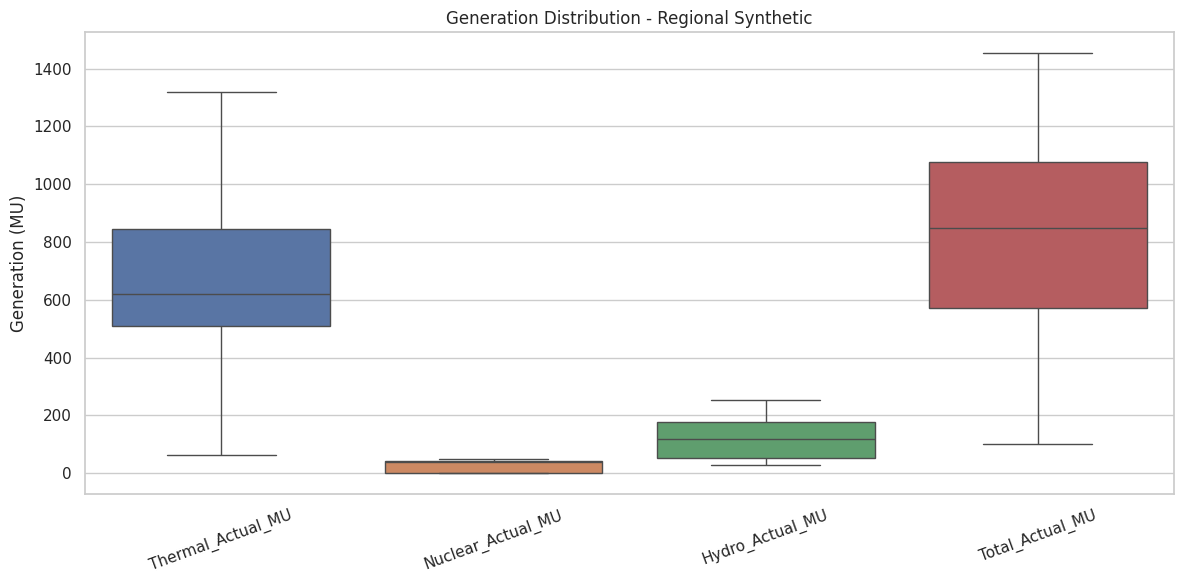

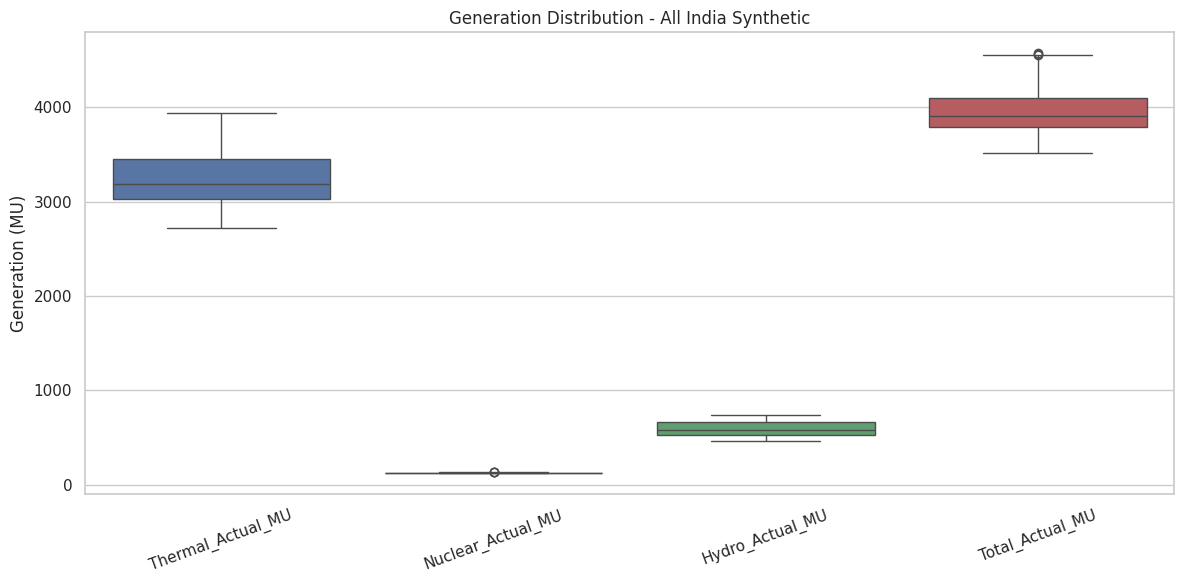

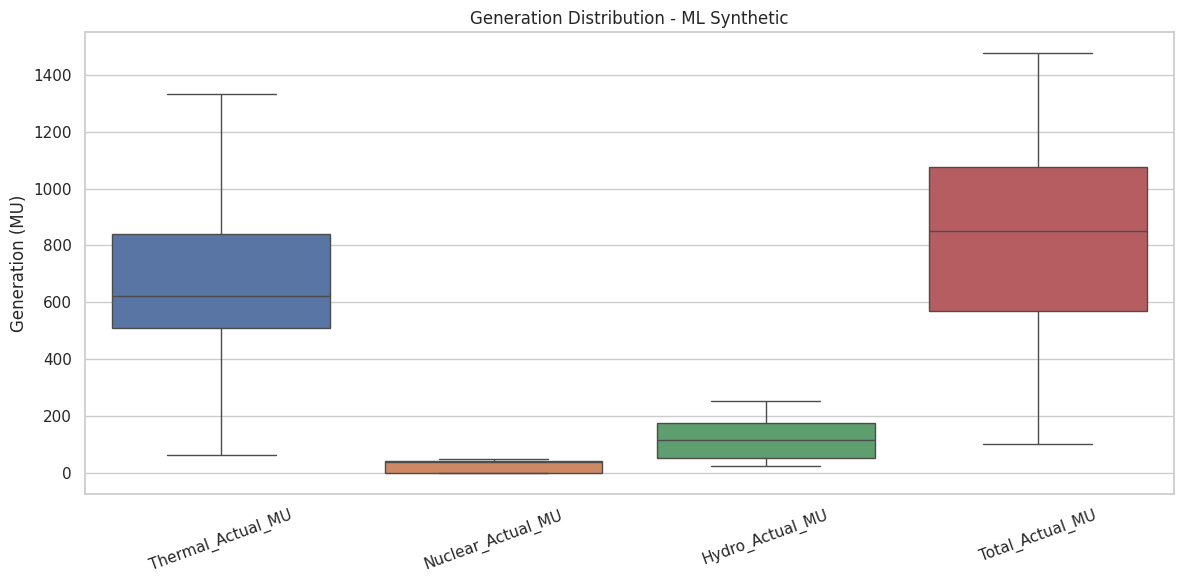

In [ ]:

# ============================================
# STEP 14: GENERATION OUTLIER VISUALIZATION
# ============================================

for name, df in datasets.items():

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df[
            [
                "Thermal_Actual_MU",
                "Nuclear_Actual_MU",
                "Hydro_Actual_MU",
                "Total_Actual_MU"
            ]
        ]
    )

    plt.title(f"Generation Distribution - {name}")
    plt.ylabel("Generation (MU)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


In [ ]:

# ============================================
# STEP 15: CREATE CLEANED DATASETS
# ============================================

clean_datasets = {}

essential_columns = [
    "Date",
    "Region",
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU",
    "Total_Actual_MU"
]

for name, df in datasets.items():

    clean_df = df.copy()

    # Convert dates
    clean_df["Date"] = pd.to_datetime(
        clean_df["Date"],
        errors="coerce"
    )

    # Remove exact duplicates
    clean_df = clean_df.drop_duplicates()

    # Remove invalid dates
    clean_df = clean_df.dropna(
        subset=["Date"]
    )

    # Remove rows missing essential fields
    clean_df = clean_df.dropna(
        subset=essential_columns
    )

    # Check negative generation values
    clean_df = clean_df[
        (clean_df[generation_columns] >= 0).all(axis=1)
    ]

    clean_datasets[name] = clean_df.reset_index(drop=True)

    print("\n", name)
    print("Original rows:", len(df))
    print("Cleaned rows:", len(clean_df))
    print("Removed rows:", len(df) - len(clean_df))



 Regional Synthetic
Original rows: 2000
Cleaned rows: 2000
Removed rows: 0

 All India Synthetic
Original rows: 2000
Cleaned rows: 2000
Removed rows: 0

 ML Synthetic
Original rows: 2000
Cleaned rows: 2000
Removed rows: 0


In [ ]:

# ============================================
# STEP 16: FINAL CLEANING REPORT
# ============================================

cleaning_report = []

for name, df in clean_datasets.items():

    cleaning_report.append({
        "Dataset": name,
        "Rows_After_Cleaning": len(df),
        "Columns": len(df.columns),
        "Missing_Values": df.isnull().sum().sum(),
        "Duplicate_Rows": df.duplicated().sum(),
        "Invalid_Dates": df["Date"].isnull().sum()
    })

cleaning_report_df = pd.DataFrame(cleaning_report)

display(cleaning_report_df)


,Dataset,Rows_After_Cleaning,Columns,Missing_Values,Duplicate_Rows,Invalid_Dates
0,Regional Synthetic,2000,28,0,0,0
1,All India Synthetic,2000,28,0,0,0
2,ML Synthetic,2000,28,0,0,0


In [ ]:

# ============================================
# STEP 17: EXPORT CLEANED DATASETS
# ============================================

for name, df in clean_datasets.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + "_cleaned.csv"
    )

    df.to_csv(filename, index=False)

    print("Saved:", filename)


Saved: regional_synthetic_cleaned.csv
Saved: all_india_synthetic_cleaned.csv
Saved: ml_synthetic_cleaned.csv


In [ ]:

# ============================================
# TAB 3: EDA INITIALIZATION
# ============================================

regional_eda = clean_datasets["Regional Synthetic"].copy()

overall_eda = clean_datasets["All India Synthetic"].copy()

ml_eda = clean_datasets["ML Synthetic"].copy()

# Sort data chronologically
regional_eda = regional_eda.sort_values(
    ["Region", "Date"]
)

overall_eda = overall_eda.sort_values("Date")

ml_eda = ml_eda.sort_values(
    ["Region", "Date"]
)

print("EDA datasets prepared successfully!")

print("Regional:", regional_eda.shape)
print("All India:", overall_eda.shape)
print("ML:", ml_eda.shape)


EDA datasets prepared successfully!
Regional: (2000, 28)
All India: (2000, 28)
ML: (2000, 28)


,Total_Generation_MU
Region,
Western,491470.187355
Southern,418002.561689
Northern,342091.429253
Eastern,239092.155865
NorthEastern,45678.224089


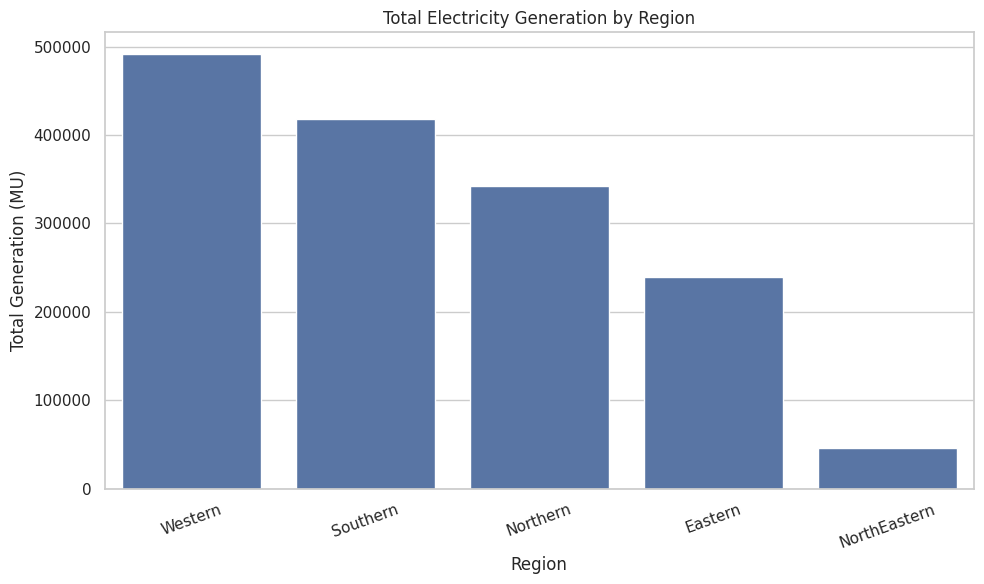

In [ ]:

# ============================================
# STEP 2: TOTAL GENERATION BY REGION
# ============================================

regional_generation = (
    regional_eda.groupby("Region")["Total_Actual_MU"]
    .sum()
    .sort_values(ascending=False)
)

display(
    regional_generation.to_frame(
        name="Total_Generation_MU"
    )
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=regional_generation.index,
    y=regional_generation.values
)

plt.title("Total Electricity Generation by Region")
plt.xlabel("Region")
plt.ylabel("Total Generation (MU)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


,Thermal,Nuclear,Hydro
Region,,,
Eastern,216316.61,0.00,22775.55
NorthEastern,31158.79,0.00,14519.43
Northern,252776.62,16800.34,72514.47
Southern,320331.64,19213.50,78457.43
Western,428709.76,15207.54,47552.88


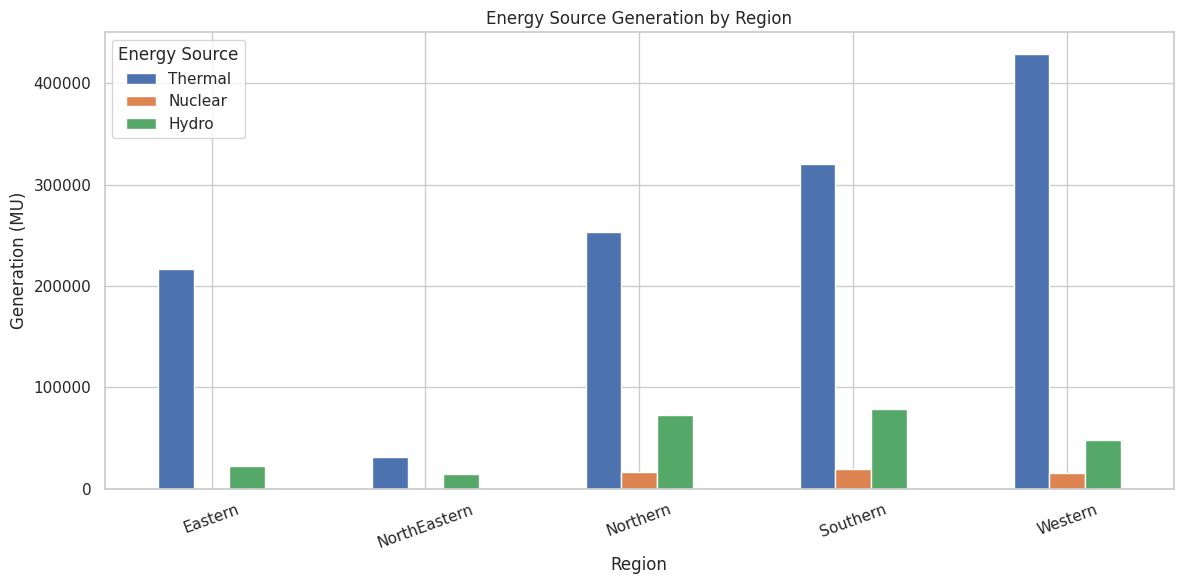

In [ ]:

# ============================================
# STEP 3: ENERGY SOURCE COMPARISON
# ============================================

source_columns = [
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU"
]

source_by_region = (
    regional_eda.groupby("Region")[source_columns]
    .sum()
)

source_by_region.columns = [
    "Thermal",
    "Nuclear",
    "Hydro"
]

display(source_by_region.round(2))

source_by_region.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Energy Source Generation by Region")
plt.xlabel("Region")
plt.ylabel("Generation (MU)")
plt.xticks(rotation=20)
plt.legend(title="Energy Source")

plt.tight_layout()
plt.show()


Average Generation Comparison:


,Average_MU
Thermal_Actual_MU,624.646710
Thermal_Estimated_MU,624.485521
Nuclear_Actual_MU,25.610690
Nuclear_Estimated_MU,25.614451
Hydro_Actual_MU,117.909879
Hydro_Estimated_MU,117.889479
Total_Actual_MU,768.167279
Total_Estimated_MU,767.989450


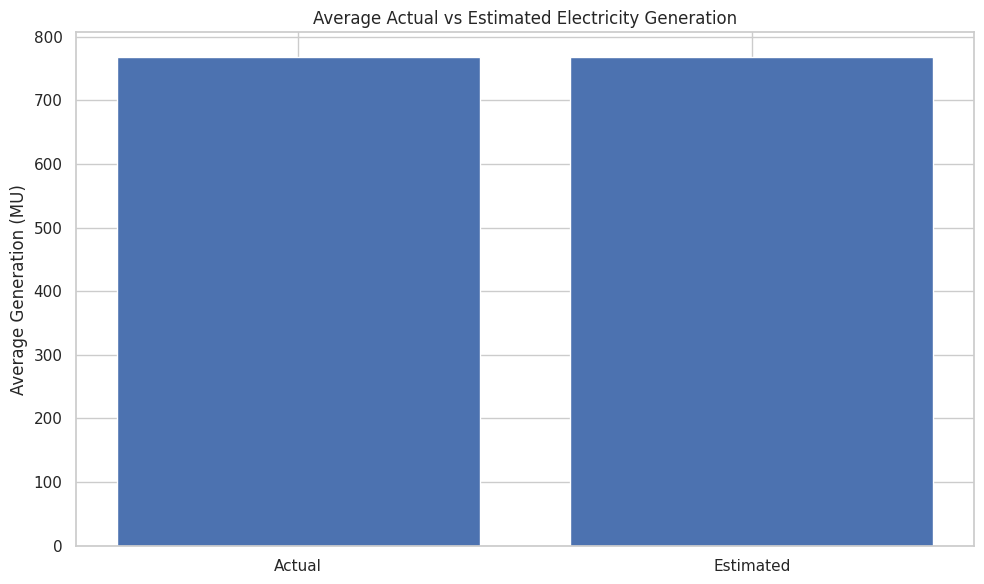

In [ ]:

# ============================================
# STEP 4: ACTUAL VS ESTIMATED GENERATION
# ============================================

comparison = regional_eda[
    [
        "Thermal_Actual_MU",
        "Thermal_Estimated_MU",
        "Nuclear_Actual_MU",
        "Nuclear_Estimated_MU",
        "Hydro_Actual_MU",
        "Hydro_Estimated_MU",
        "Total_Actual_MU",
        "Total_Estimated_MU"
    ]
].mean()

print("Average Generation Comparison:")
display(comparison.to_frame(name="Average_MU"))

plt.figure(figsize=(10, 6))

plt.bar(
    ["Actual", "Estimated"],
    [
        regional_eda["Total_Actual_MU"].mean(),
        regional_eda["Total_Estimated_MU"].mean()
    ]
)

plt.title("Average Actual vs Estimated Electricity Generation")
plt.ylabel("Average Generation (MU)")

plt.tight_layout()
plt.show()


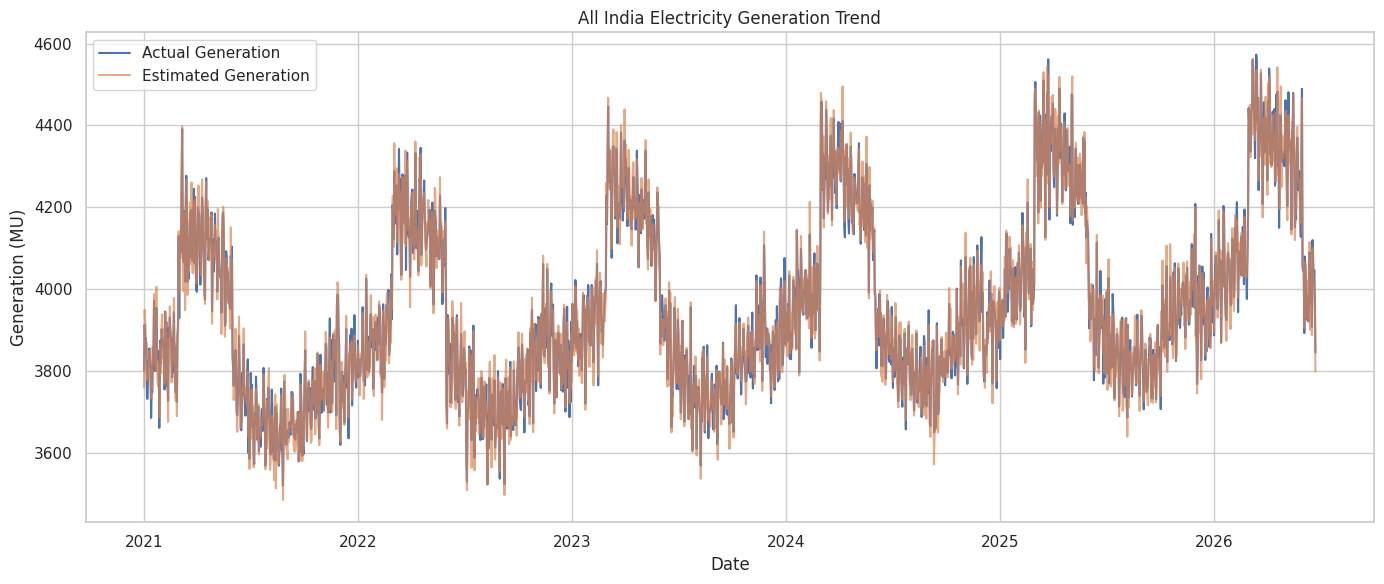

In [ ]:

# ============================================
# STEP 5: NATIONAL GENERATION TREND
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    overall_eda["Date"],
    overall_eda["Total_Actual_MU"],
    label="Actual Generation"
)

plt.plot(
    overall_eda["Date"],
    overall_eda["Total_Estimated_MU"],
    label="Estimated Generation",
    alpha=0.7
)

plt.title("All India Electricity Generation Trend")
plt.xlabel("Date")
plt.ylabel("Generation (MU)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


,Average_Generation_MU
Season,
Winter,3918.996949
Summer,4232.892167
Monsoon,3782.063123
Post-Monsoon,3869.086487


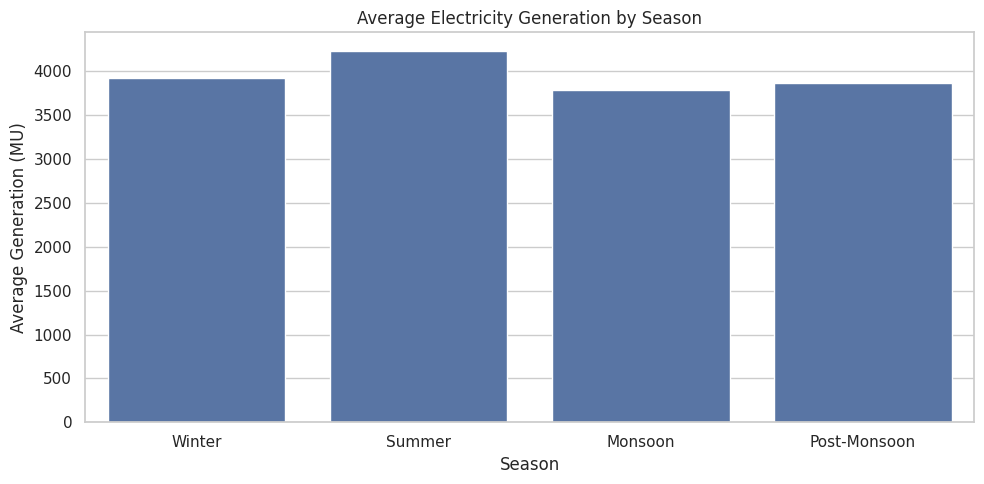

In [ ]:

# ============================================
# STEP 7: SEASONAL GENERATION ANALYSIS
# ============================================

seasonal_generation = (
    overall_eda.groupby("Season")["Total_Actual_MU"]
    .mean()
    .reindex([
        "Winter",
        "Summer",
        "Monsoon",
        "Post-Monsoon"
    ])
)

display(
    seasonal_generation.to_frame(
        name="Average_Generation_MU"
    )
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=seasonal_generation.index,
    y=seasonal_generation.values
)

plt.title("Average Electricity Generation by Season")
plt.xlabel("Season")
plt.ylabel("Average Generation (MU)")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# TAB 4: FEATURE ENGINEERING
# STEP 1: PREPARE DATASET
# ============================================

# Use the cleaned regional dataset
feature_df = clean_datasets["Regional Synthetic"].copy()

# Sort by region and date
feature_df = feature_df.sort_values(
    ["Region", "Date"]
).reset_index(drop=True)

# Ensure Date is datetime
feature_df["Date"] = pd.to_datetime(
    feature_df["Date"]
)

print("Dataset prepared successfully!")

display(feature_df.head())


Dataset prepared successfully!


,Date,Region,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Season,Latitude,...,Nuclear_Actual_MU,Nuclear_Estimated_MU,Hydro_Actual_MU,Hydro_Estimated_MU,Total_Actual_MU,Total_Estimated_MU,Estimation_Error_MU,Thermal_Share_Pct,Nuclear_Share_Pct,Hydro_Share_Pct
0,2024-01-01,Eastern,synthetic,2024,1,1,0,0,Winter,23.0,...,0.0,0.0,53.323412,55.050578,599.132460,608.306626,9.174165,91.099896,0.0,8.900104
1,2024-01-02,Eastern,synthetic,2024,1,2,1,0,Winter,23.0,...,0.0,0.0,62.578521,63.837933,606.941823,604.509905,-2.431918,89.689536,0.0,10.310464
2,2024-01-03,Eastern,synthetic,2024,1,3,2,0,Winter,23.0,...,0.0,0.0,55.729490,58.980196,593.323132,603.224482,9.901350,90.607228,0.0,9.392772
3,2024-01-04,Eastern,synthetic,2024,1,4,3,0,Winter,23.0,...,0.0,0.0,62.675418,58.607419,575.122301,576.232545,1.110243,89.102245,0.0,10.897755
4,2024-01-05,Eastern,synthetic,2024,1,5,4,0,Winter,23.0,...,0.0,0.0,60.756581,59.134695,584.796386,566.732993,-18.063393,89.610644,0.0,10.389356


In [ ]:

# ============================================
# STEP 2: CALENDAR FEATURES
# ============================================

# Extract year, month and day
feature_df["Year"] = feature_df["Date"].dt.year
feature_df["Month"] = feature_df["Date"].dt.month
feature_df["Day"] = feature_df["Date"].dt.day

# Day of week: Monday = 0, Sunday = 6
feature_df["DayOfWeek"] = feature_df["Date"].dt.dayofweek

# Weekend indicator
feature_df["Is_Weekend"] = (
    feature_df["DayOfWeek"] >= 5
).astype(int)

# Quarter
feature_df["Quarter"] = (
    feature_df["Date"].dt.quarter
)

# Display results
display(
    feature_df[
        [
            "Date",
            "Year",
            "Month",
            "Day",
            "DayOfWeek",
            "Is_Weekend",
            "Quarter"
        ]
    ].head(10)
)


,Date,Year,Month,Day,DayOfWeek,Is_Weekend,Quarter
0,2024-01-01,2024,1,1,0,0,1
1,2024-01-02,2024,1,2,1,0,1
2,2024-01-03,2024,1,3,2,0,1
3,2024-01-04,2024,1,4,3,0,1
4,2024-01-05,2024,1,5,4,0,1
5,2024-01-06,2024,1,6,5,1,1
6,2024-01-07,2024,1,7,6,1,1
7,2024-01-08,2024,1,8,0,0,1
8,2024-01-09,2024,1,9,1,0,1
9,2024-01-10,2024,1,10,2,0,1


In [ ]:

# ============================================
# STEP 3: SEASON ENCODING
# ============================================

feature_df["Season"] = feature_df["Season"].astype(str)

feature_df = pd.get_dummies(
    feature_df,
    columns=["Season"],
    prefix="Season",
    dtype=int
)

print("Season encoding completed!")

season_columns = [
    col for col in feature_df.columns
    if col.startswith("Season_")
]

display(
    feature_df[
        ["Date", "Region"] + season_columns
    ].head()
)


Season encoding completed!


,Date,Region,Season_Monsoon,Season_Post-Monsoon,Season_Summer,Season_Winter
0,2024-01-01,Eastern,0,0,0,1
1,2024-01-02,Eastern,0,0,0,1
2,2024-01-03,Eastern,0,0,0,1
3,2024-01-04,Eastern,0,0,0,1
4,2024-01-05,Eastern,0,0,0,1


In [ ]:

# ============================================
# STEP 4: CREATE LAG FEATURES
# ============================================

target_columns = [
    "Total_Actual_MU",
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU"
]

lag_periods = [1, 7, 30]

for col in target_columns:

    for lag in lag_periods:

        feature_df[f"{col}_Lag_{lag}"] = (
            feature_df.groupby("Region")[col]
            .shift(lag)
        )

print("Lag features created successfully!")

display(
    feature_df[
        [
            "Date",
            "Region",
            "Total_Actual_MU",
            "Total_Actual_MU_Lag_1",
            "Total_Actual_MU_Lag_7",
            "Total_Actual_MU_Lag_30"
        ]
    ].head(35)
)


Lag features created successfully!


,Date,Region,Total_Actual_MU,Total_Actual_MU_Lag_1,Total_Actual_MU_Lag_7,Total_Actual_MU_Lag_30
0,2024-01-01,Eastern,599.132460,NaN,NaN,NaN
1,2024-01-02,Eastern,606.941823,599.132460,NaN,NaN
2,2024-01-03,Eastern,593.323132,606.941823,NaN,NaN
3,2024-01-04,Eastern,575.122301,593.323132,NaN,NaN
4,2024-01-05,Eastern,584.796386,575.122301,NaN,NaN
5,2024-01-06,Eastern,616.179537,584.796386,NaN,NaN
6,2024-01-07,Eastern,613.615129,616.179537,NaN,NaN
7,2024-01-08,Eastern,606.297688,613.615129,599.132460,NaN
8,2024-01-09,Eastern,625.029173,606.297688,606.941823,NaN
9,2024-01-10,Eastern,626.770983,625.029173,593.323132,NaN


In [ ]:

# ============================================
# STEP 5: ROLLING AVERAGE FEATURES
# ============================================

for col in target_columns:

    # Previous 7-day average
    feature_df[f"{col}_Rolling_7"] = (
        feature_df.groupby("Region")[col]
        .transform(
            lambda x: x.shift(1).rolling(
                window=7,
                min_periods=7
            ).mean()
        )
    )

    # Previous 30-day average
    feature_df[f"{col}_Rolling_30"] = (
        feature_df.groupby("Region")[col]
        .transform(
            lambda x: x.shift(1).rolling(
                window=30,
                min_periods=30
            ).mean()
        )
    )

print("Rolling average features created!")

display(
    feature_df[
        [
            "Date",
            "Region",
            "Total_Actual_MU",
            "Total_Actual_MU_Rolling_7",
            "Total_Actual_MU_Rolling_30"
        ]
    ].tail(10)
)


Rolling average features created!


,Date,Region,Total_Actual_MU,Total_Actual_MU_Rolling_7,Total_Actual_MU_Rolling_30
1990,2025-01-25,Western,1206.033924,1237.846963,1235.942798
1991,2025-01-26,Western,1248.637586,1236.184603,1236.271920
1992,2025-01-27,Western,1231.575918,1240.316146,1238.219152
1993,2025-01-28,Western,1205.180178,1242.238220,1238.315650
1994,2025-01-29,Western,1220.573721,1235.179710,1237.813611
1995,2025-01-30,Western,1232.607299,1224.833245,1237.630048
1996,2025-01-31,Western,1218.726536,1217.044920,1237.134783
1997,2025-02-01,Western,1263.618456,1223.333595,1235.297762
1998,2025-02-02,Western,1213.161518,1231.559956,1234.698325
1999,2025-02-03,Western,1283.195726,1226.491947,1233.638896


In [ ]:

# ============================================
# STEP 6: HISTORICAL GENERATION GROWTH
# ============================================

for col in target_columns:

    previous = feature_df.groupby("Region")[col].shift(1)

    feature_df[f"{col}_Growth_Pct"] = (
        (feature_df[col] - previous)
        / previous.replace(0, np.nan)
    ) * 100

print("Generation growth features created!")

display(
    feature_df[
        [
            "Date",
            "Region",
            "Total_Actual_MU",
            "Total_Actual_MU_Growth_Pct"
        ]
    ].tail(10)
)


Generation growth features created!


,Date,Region,Total_Actual_MU,Total_Actual_MU_Growth_Pct
1990,2025-01-25,Western,1206.033924,2.666890
1991,2025-01-26,Western,1248.637586,3.532543
1992,2025-01-27,Western,1231.575918,-1.366423
1993,2025-01-28,Western,1205.180178,-2.143249
1994,2025-01-29,Western,1220.573721,1.277281
1995,2025-01-30,Western,1232.607299,0.985895
1996,2025-01-31,Western,1218.726536,-1.126130
1997,2025-02-01,Western,1263.618456,3.683511
1998,2025-02-02,Western,1213.161518,-3.993052
1999,2025-02-03,Western,1283.195726,5.772868


In [ ]:

# ============================================
# STEP 7: REGION ENCODING
# ============================================

feature_df = pd.get_dummies(
    feature_df,
    columns=["Region"],
    prefix="Region",
    dtype=int
)

region_columns = [
    col for col in feature_df.columns
    if col.startswith("Region_")
]

print("Regional encoding completed!")

display(
    feature_df[
        ["Date"] + region_columns
    ].head()
)


Regional encoding completed!


,Date,Region_Eastern,Region_NorthEastern,Region_Northern,Region_Southern,Region_Western
0,2024-01-01,1,0,0,0,0
1,2024-01-02,1,0,0,0,0
2,2024-01-03,1,0,0,0,0
3,2024-01-04,1,0,0,0,0
4,2024-01-05,1,0,0,0,0


In [ ]:

# ============================================
# STEP 8: HANDLE LAG-RELATED MISSING VALUES
# ============================================

feature_df = feature_df.dropna().reset_index(drop=True)

print("Feature engineering dataset prepared!")

print("Final shape:", feature_df.shape)

print("\nMissing values:")
print(feature_df.isnull().sum().sum())

display(feature_df.head())


Feature engineering dataset prepared!
Final shape: (1110, 60)

Missing values:
0


,Date,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Latitude,Longitude,Centroid_Lat,...,Hydro_Actual_MU_Rolling_30,Total_Actual_MU_Growth_Pct,Thermal_Actual_MU_Growth_Pct,Nuclear_Actual_MU_Growth_Pct,Hydro_Actual_MU_Growth_Pct,Region_Eastern,Region_NorthEastern,Region_Northern,Region_Southern,Region_Western
0,2024-01-31,synthetic,2024,1,31,2,0,29.5,77.5,29.0,...,177.910118,5.285887,7.651209,2.969718,-1.746641,0,0,1,0,0
1,2024-02-01,synthetic,2024,2,1,3,0,29.5,77.5,29.0,...,178.998944,-6.945847,-2.159535,-0.984900,-24.973686,0,0,1,0,0
2,2024-02-02,synthetic,2024,2,2,4,0,29.5,77.5,29.0,...,177.984014,3.633796,-1.405932,0.576999,27.457250,0,0,1,0,0
3,2024-02-03,synthetic,2024,2,3,5,1,29.5,77.5,29.0,...,178.127566,-2.468132,-3.284239,-0.140270,-0.141028,0,0,1,0,0
4,2024-02-04,synthetic,2024,2,4,6,1,29.5,77.5,29.0,...,178.463281,0.034443,1.052568,0.958824,-3.650274,0,0,1,0,0


In [ ]:

# ============================================
# STEP 9: FINAL FEATURE INSPECTION
# ============================================

print("Total Features:", len(feature_df.columns))

print("\nFinal Columns:")

for col in feature_df.columns:
    print(col)

print("\nFinal Dataset Information:")
feature_df.info()


Total Features: 60

Final Columns:
Date
Data_Source
Year
Month
Day
DayOfWeek
Is_Weekend
Latitude
Longitude
Centroid_Lat
Centroid_Lon
Num_States_UTs
Area_km2
National_Share_pct
Thermal_Actual_MU
Thermal_Estimated_MU
Nuclear_Actual_MU
Nuclear_Estimated_MU
Hydro_Actual_MU
Hydro_Estimated_MU
Total_Actual_MU
Total_Estimated_MU
Estimation_Error_MU
Thermal_Share_Pct
Nuclear_Share_Pct
Hydro_Share_Pct
Quarter
Season_Monsoon
Season_Post-Monsoon
Season_Summer
Season_Winter
Total_Actual_MU_Lag_1
Total_Actual_MU_Lag_7
Total_Actual_MU_Lag_30
Thermal_Actual_MU_Lag_1
Thermal_Actual_MU_Lag_7
Thermal_Actual_MU_Lag_30
Nuclear_Actual_MU_Lag_1
Nuclear_Actual_MU_Lag_7
Nuclear_Actual_MU_Lag_30
Hydro_Actual_MU_Lag_1
Hydro_Actual_MU_Lag_7
Hydro_Actual_MU_Lag_30
Total_Actual_MU_Rolling_7
Total_Actual_MU_Rolling_30
Thermal_Actual_MU_Rolling_7
Thermal_Actual_MU_Rolling_30
Nuclear_Actual_MU_Rolling_7
Nuclear_Actual_MU_Rolling_30
Hydro_Actual_MU_Rolling_7
Hydro_Actual_MU_Rolling_30
Total_Actual_MU_Growth_Pct
Therma

In [ ]:

# ============================================
# TAB 5: GRADIENT DESCENT FROM SCRATCH
# STEP 1: PREPARE DATA
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the feature-engineered dataset
ml_df = feature_df.copy()

# Target variable
target = "Total_Actual_MU"

# Calendar features
calendar_features = [
    "Year", "Month", "Day",
    "DayOfWeek", "Is_Weekend", "Quarter"
]

# Season encoding
season_features = [
    col for col in ml_df.columns
    if col.startswith("Season_")
]

# Region encoding
region_features = [
    col for col in ml_df.columns
    if col.startswith("Region_")
]

# Historical lag features
lag_features = [
    col for col in ml_df.columns
    if "_Lag_" in col
]

# Historical rolling average features
rolling_features = [
    col for col in ml_df.columns
    if "_Rolling_" in col
]

# Combine permitted input features
feature_columns = (
    calendar_features
    + season_features
    + region_features
    + lag_features
    + rolling_features
)

X = ml_df[feature_columns].copy()
y = ml_df[target].copy()

print("Input features:", X.shape)
print("Target variable:", y.shape)

print("\nSelected features:")
print(feature_columns)

print("\nTarget variable:", target)


Input features: (1110, 35)
Target variable: (1110,)

Selected features:
['Year', 'Month', 'Day', 'DayOfWeek', 'Is_Weekend', 'Quarter', 'Season_Monsoon', 'Season_Post-Monsoon', 'Season_Summer', 'Season_Winter', 'Region_Eastern', 'Region_NorthEastern', 'Region_Northern', 'Region_Southern', 'Region_Western', 'Total_Actual_MU_Lag_1', 'Total_Actual_MU_Lag_7', 'Total_Actual_MU_Lag_30', 'Thermal_Actual_MU_Lag_1', 'Thermal_Actual_MU_Lag_7', 'Thermal_Actual_MU_Lag_30', 'Nuclear_Actual_MU_Lag_1', 'Nuclear_Actual_MU_Lag_7', 'Nuclear_Actual_MU_Lag_30', 'Hydro_Actual_MU_Lag_1', 'Hydro_Actual_MU_Lag_7', 'Hydro_Actual_MU_Lag_30', 'Total_Actual_MU_Rolling_7', 'Total_Actual_MU_Rolling_30', 'Thermal_Actual_MU_Rolling_7', 'Thermal_Actual_MU_Rolling_30', 'Nuclear_Actual_MU_Rolling_7', 'Nuclear_Actual_MU_Rolling_30', 'Hydro_Actual_MU_Rolling_7', 'Hydro_Actual_MU_Rolling_30']

Target variable: Total_Actual_MU


In [ ]:

# ============================================
# STEP 2: CHRONOLOGICAL TRAIN-TEST SPLIT
# ============================================

unique_dates = np.sort(
    ml_df["Date"].unique()
)

split_index = int(len(unique_dates) * 0.80)

cutoff_date = unique_dates[split_index]

train_mask = ml_df["Date"] < cutoff_date
test_mask = ml_df["Date"] >= cutoff_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training cutoff date:", cutoff_date)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining date range:")
print(ml_df.loc[train_mask, "Date"].min(),
      "to",
      ml_df.loc[train_mask, "Date"].max())

print("\nTesting date range:")
print(ml_df.loc[test_mask, "Date"].min(),
      "to",
      ml_df.loc[test_mask, "Date"].max())


Training cutoff date: 2024-11-22T00:00:00.000000000

Training records: 888
Testing records: 222

Training date range:
2024-01-31 00:00:00 to 2024-11-21 00:00:00

Testing date range:
2024-11-22 00:00:00 to 2025-02-03 00:00:00


In [ ]:

# ============================================
# STEP 3: FEATURE SCALING
# ============================================

# Scale input features
X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)

X_test_scaled = X_scaler.transform(X_test)

# Scale target variable
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

print("Feature scaling completed!")

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Feature scaling completed!
Scaled training shape: (888, 35)
Scaled testing shape: (222, 35)


In [ ]:

# ============================================
# STEP 4: PREDICTION FUNCTION
# ============================================

def predict(X, weights, bias):

    predictions = np.dot(X, weights) + bias

    return predictions


# Initialize weights and bias
n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)

bias = 0.0

# Generate sample predictions
sample_predictions = predict(
    X_train_scaled[:5],
    weights,
    bias
)

print("Initial predictions:")
print(sample_predictions)


Initial predictions:
[0. 0. 0. 0. 0.]


In [ ]:

# ============================================
# STEP 5: MEAN SQUARED ERROR
# ============================================

def calculate_mse(y_actual, y_predicted):

    error = y_actual - y_predicted

    mse = np.mean(error ** 2)

    return mse


# Test MSE calculation
initial_predictions = predict(
    X_train_scaled,
    weights,
    bias
)

initial_mse = calculate_mse(
    y_train_scaled,
    initial_predictions
)

print("Initial MSE:", initial_mse)


Initial MSE: 0.9999999999999998


In [ ]:

# ============================================
# STEP 6: GRADIENT CALCULATION
# ============================================

def calculate_gradients(X, y, weights, bias):

    n = len(y)

    predictions = predict(X, weights, bias)

    errors = predictions - y

    dw = (2/n) * np.dot(X.T, errors)

    db = (2/n) * np.sum(errors)

    return dw, db


dw, db = calculate_gradients(
    X_train_scaled,
    y_train_scaled,
    weights,
    bias
)

print("Weight gradients:")
print(dw)

print("\nBias gradient:")
print(db)


Weight gradients:
[ 0.          0.43593764  0.00430845  0.11579945  0.11632478  0.40251694
  0.440009    0.1553538  -0.59830725  0.004009    0.          0.
  1.58749173  0.01515197 -1.6026437  -1.92616234 -1.92314813 -1.85667223
 -1.91708564 -1.91367898 -1.84863317  0.69430174  0.69477536  0.70582973
  1.42391734  1.42651849  1.37957051 -1.95040701 -1.93780218 -1.93120005
 -1.91996082  0.70034649  0.7047943   1.46820196  1.48355898]

Bias gradient:
-5.12102872619892e-16


In [ ]:

# ============================================
# STEP 7: BATCH GRADIENT DESCENT
# ============================================

def batch_gradient_descent(
    X, y, learning_rate=0.01, epochs=500
):

    n_features = X.shape[1]

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Predictions
        predictions = predict(X, weights, bias)

        # Calculate error
        error = predictions - y

        # Calculate gradients
        dw = (2/len(y)) * np.dot(X.T, error)

        db = (2/len(y)) * np.sum(error)

        # Update parameters
        weights -= learning_rate * dw

        bias -= learning_rate * db

        # Calculate loss after update
        updated_predictions = predict(X, weights, bias)

        loss = calculate_mse(y, updated_predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


batch_weights, batch_bias, batch_losses = (
    batch_gradient_descent(
        X_train_scaled,
        y_train_scaled,
        learning_rate=0.01,
        epochs=500
    )
)

print("Batch Gradient Descent completed!")

print("Initial loss:", batch_losses[0])
print("Final loss:", batch_losses[-1])


Batch Gradient Descent completed!
Initial loss: 0.5338858494481636
Final loss: 0.04127124019553353


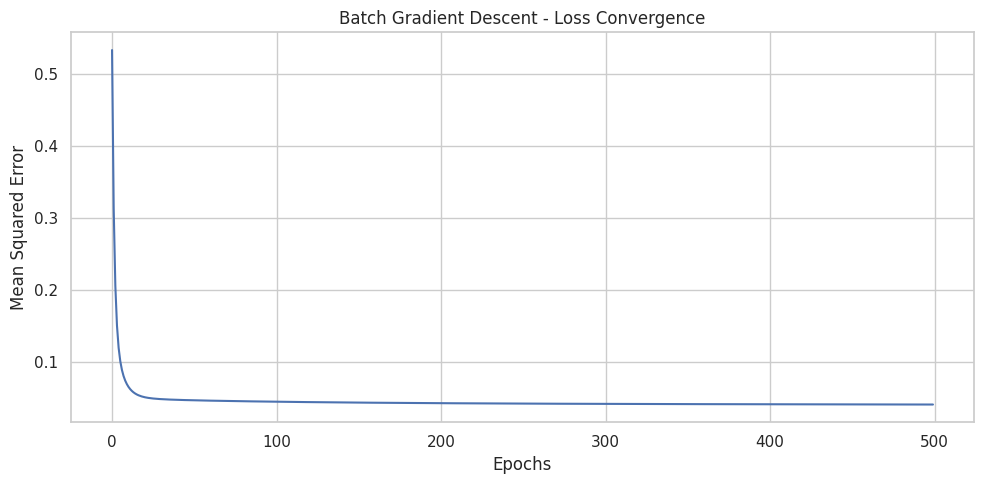

In [ ]:

# ============================================
# STEP 8: BATCH LOSS CURVE
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(batch_losses)

plt.title("Batch Gradient Descent - Loss Convergence")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 9: STOCHASTIC GRADIENT DESCENT
# ============================================

def stochastic_gradient_descent(
    X, y, learning_rate=0.005,
    epochs=100, random_state=42
):

    rng = np.random.default_rng(random_state)

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Shuffle observations every epoch
        indices = rng.permutation(n_samples)

        for i in indices:

            xi = X[i]
            yi = y[i]

            # Prediction for one observation
            prediction = np.dot(xi, weights) + bias

            error = prediction - yi

            # Gradients for one observation
            dw = 2 * xi * error

            db = 2 * error

            # Update weights and bias
            weights -= learning_rate * dw

            bias -= learning_rate * db

        # Calculate full training loss after each epoch
        predictions = predict(X, weights, bias)

        loss = calculate_mse(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


sgd_weights, sgd_bias, sgd_losses = (
    stochastic_gradient_descent(
        X_train_scaled,
        y_train_scaled,
        learning_rate=0.005,
        epochs=100
    )
)

print("SGD completed!")

print("Initial loss:", sgd_losses[0])
print("Final loss:", sgd_losses[-1])


SGD completed!
Initial loss: 0.060995106410783886
Final loss: 0.04787172185692837


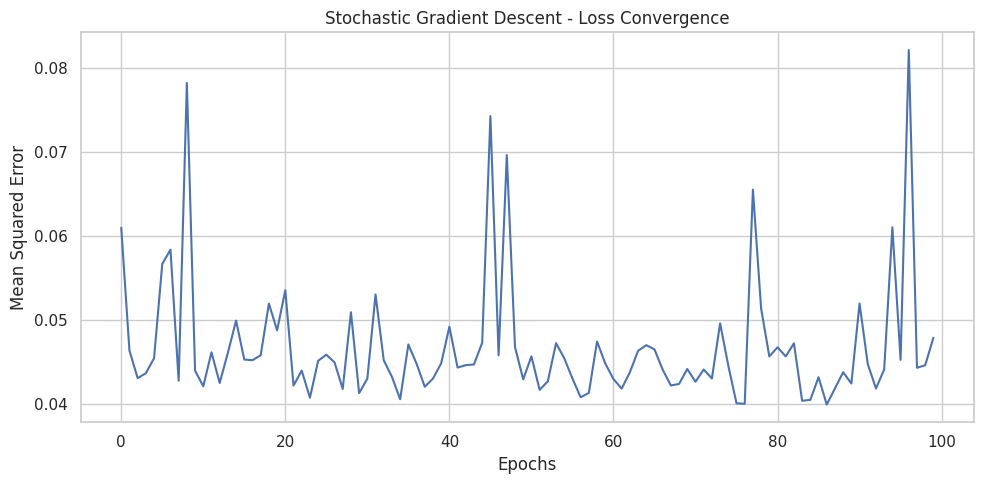

In [ ]:

# ============================================
# STEP 10: SGD LOSS CURVE
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(sgd_losses)

plt.title("Stochastic Gradient Descent - Loss Convergence")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 11: MINI-BATCH GRADIENT DESCENT
# ============================================

def mini_batch_gradient_descent(
    X, y,
    learning_rate=0.01,
    epochs=200,
    batch_size=32,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Shuffle training records
        indices = rng.permutation(n_samples)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Process small batches
        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            predictions = predict(
                X_batch,
                weights,
                bias
            )

            errors = predictions - y_batch

            # Calculate gradients
            dw = (
                2 / len(y_batch)
            ) * np.dot(X_batch.T, errors)

            db = (
                2 / len(y_batch)
            ) * np.sum(errors)

            # Update parameters
            weights -= learning_rate * dw

            bias -= learning_rate * db

        # Calculate training loss
        predictions = predict(X, weights, bias)

        loss = calculate_mse(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


mini_weights, mini_bias, mini_losses = (
    mini_batch_gradient_descent(
        X_train_scaled,
        y_train_scaled,
        learning_rate=0.01,
        epochs=200,
        batch_size=32
    )
)

print("Mini-batch Gradient Descent completed!")

print("Initial loss:", mini_losses[0])
print("Final loss:", mini_losses[-1])


Mini-batch Gradient Descent completed!
Initial loss: 0.04987929242889227
Final loss: 0.039420505501682565


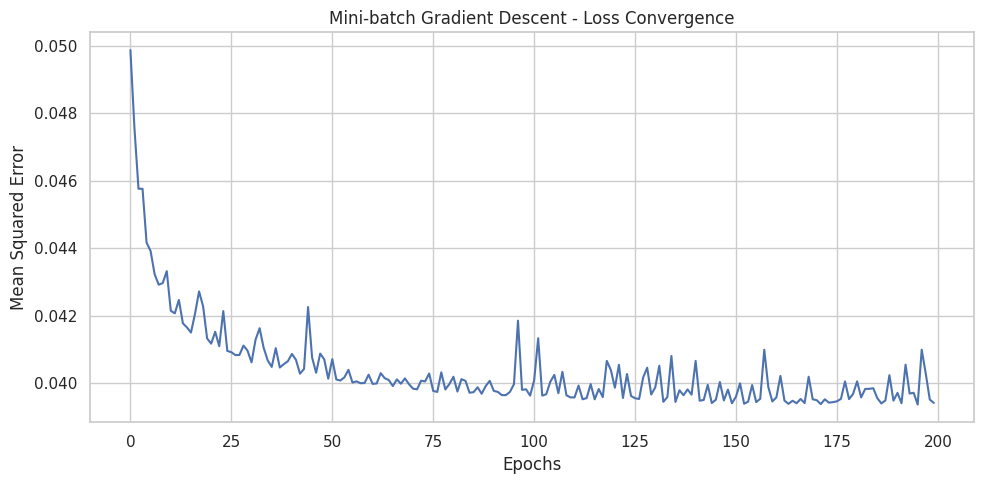

In [ ]:

# ============================================
# STEP 12: MINI-BATCH LOSS CURVE
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(mini_losses)

plt.title("Mini-batch Gradient Descent - Loss Convergence")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.grid(True)
plt.tight_layout()
plt.show()


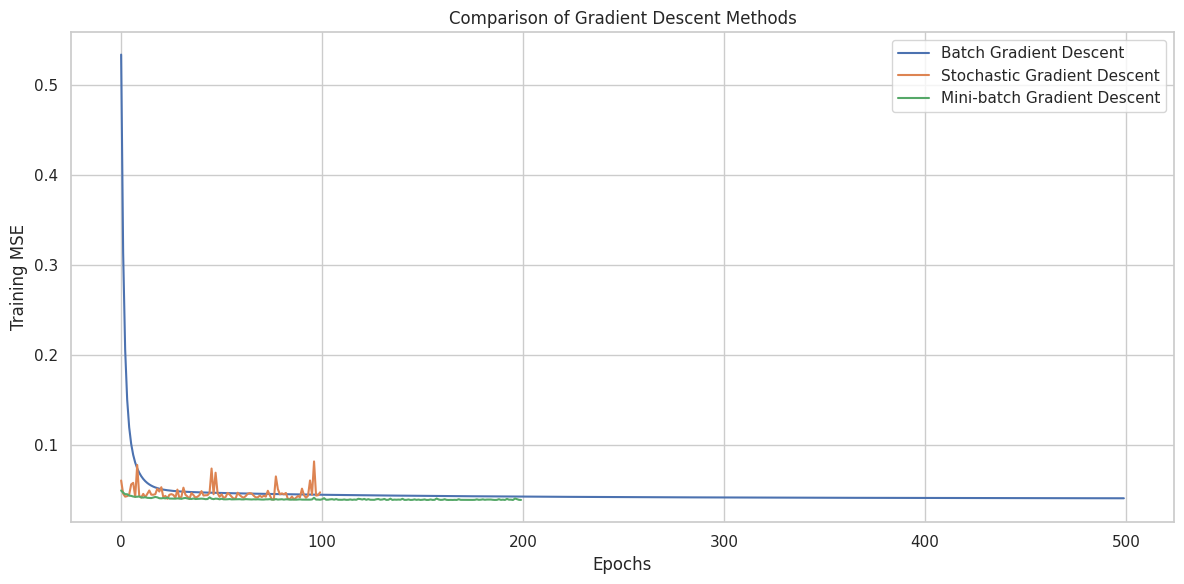

In [ ]:

# ============================================
# STEP 13: COMPARE GRADIENT DESCENT METHODS
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    batch_losses,
    label="Batch Gradient Descent"
)

plt.plot(
    sgd_losses,
    label="Stochastic Gradient Descent"
)

plt.plot(
    mini_losses,
    label="Mini-batch Gradient Descent"
)

plt.title("Comparison of Gradient Descent Methods")
plt.xlabel("Epochs")
plt.ylabel("Training MSE")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


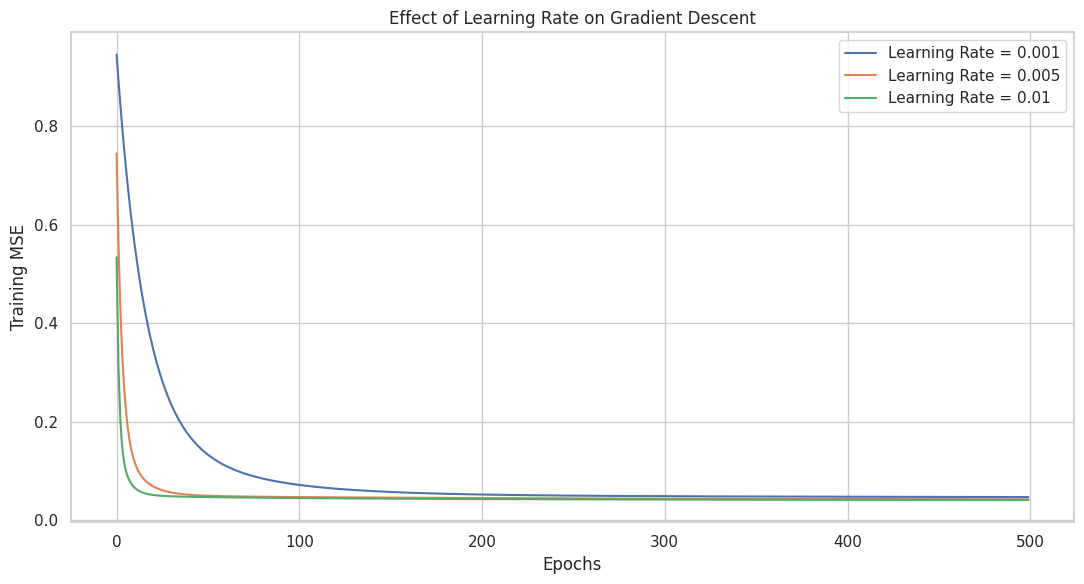

In [ ]:

# ============================================
# STEP 14: LEARNING RATE EXPERIMENT
# ============================================

learning_rates = [0.001, 0.005, 0.01]

plt.figure(figsize=(11, 6))

for lr in learning_rates:

    weights_lr, bias_lr, losses_lr = (
        batch_gradient_descent(
            X_train_scaled,
            y_train_scaled,
            learning_rate=lr,
            epochs=500
        )
    )

    plt.plot(
        losses_lr,
        label=f"Learning Rate = {lr}"
    )

plt.title("Effect of Learning Rate on Gradient Descent")
plt.xlabel("Epochs")
plt.ylabel("Training MSE")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 15: SCIKIT-LEARN LINEAR REGRESSION
# ============================================

sklearn_model = LinearRegression()

sklearn_model.fit(
    X_train_scaled,
    y_train_scaled
)

print("Scikit-learn Linear Regression trained!")

print("Number of coefficients:",
      len(sklearn_model.coef_))

print("Intercept:",
      sklearn_model.intercept_)


Scikit-learn Linear Regression trained!
Number of coefficients: 35
Intercept: 5.267043813822572e-16


In [ ]:

# ============================================
# STEP 16: GENERATE TEST PREDICTIONS
# ============================================

# Batch GD prediction
batch_pred_scaled = predict(
    X_test_scaled,
    batch_weights,
    batch_bias
)

# SGD prediction
sgd_pred_scaled = predict(
    X_test_scaled,
    sgd_weights,
    sgd_bias
)

# Mini-batch prediction
mini_pred_scaled = predict(
    X_test_scaled,
    mini_weights,
    mini_bias
)

# Scikit-learn prediction
sklearn_pred_scaled = sklearn_model.predict(
    X_test_scaled
)

# Convert predictions back to original MU scale

batch_pred = y_scaler.inverse_transform(
    batch_pred_scaled.reshape(-1, 1)
).ravel()

sgd_pred = y_scaler.inverse_transform(
    sgd_pred_scaled.reshape(-1, 1)
).ravel()

mini_pred = y_scaler.inverse_transform(
    mini_pred_scaled.reshape(-1, 1)
).ravel()

sklearn_pred = y_scaler.inverse_transform(
    sklearn_pred_scaled.reshape(-1, 1)
).ravel()

print("Predictions generated successfully!")


Predictions generated successfully!


In [ ]:

# ============================================
# STEP 17: MODEL EVALUATION
# ============================================

def evaluate_model(y_actual, y_predicted):

    mae = mean_absolute_error(
        y_actual, y_predicted
    )

    mse = mean_squared_error(
        y_actual, y_predicted
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_actual, y_predicted
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2_Score": r2
    }


model_predictions = {
    "Batch Gradient Descent": batch_pred,
    "Stochastic Gradient Descent": sgd_pred,
    "Mini-batch Gradient Descent": mini_pred,
    "Scikit-learn Linear Regression": sklearn_pred
}

results = []

for name, predictions in model_predictions.items():

    metrics = evaluate_model(
        y_test,
        predictions
    )

    metrics["Model"] = name

    results.append(metrics)


comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.set_index("Model")

display(comparison_df.round(4))


,MAE,MSE,RMSE,R2_Score
Model,,,,
Batch Gradient Descent,27.0937,1195.3145,34.5733,0.9549
Stochastic Gradient Descent,29.1024,1393.1086,37.3244,0.9474
Mini-batch Gradient Descent,27.9534,1278.1455,35.7512,0.9518
Scikit-learn Linear Regression,26.7435,1182.3820,34.3858,0.9554


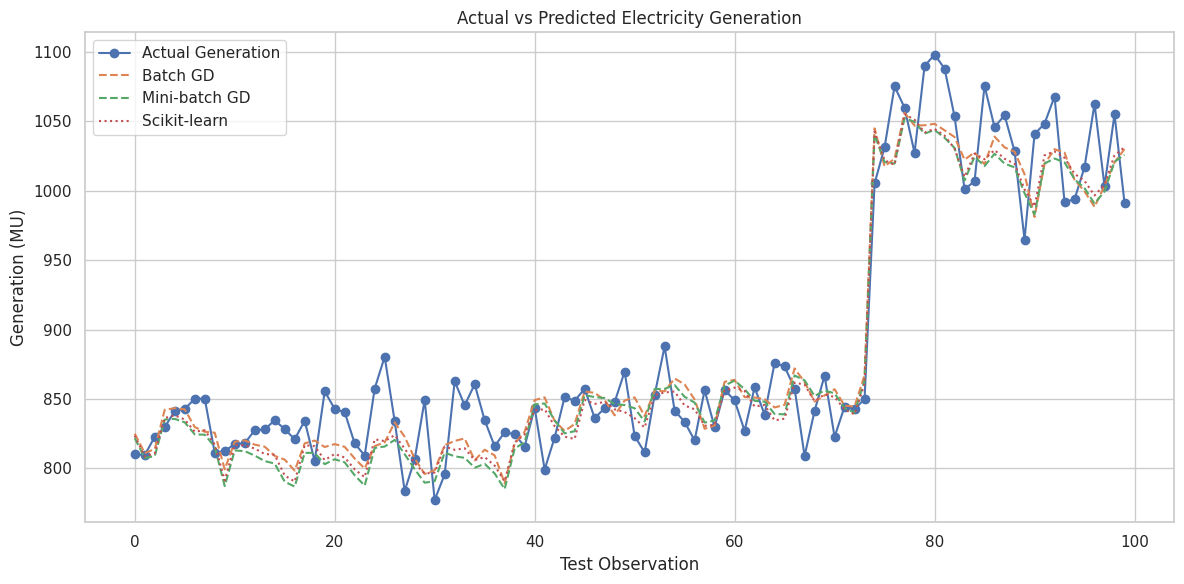

In [ ]:

# ============================================
# STEP 18: ACTUAL VS PREDICTED
# ============================================

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.to_numpy()[:100],
    label="Actual Generation",
    marker="o"
)

plt.plot(
    batch_pred[:100],
    label="Batch GD",
    linestyle="--"
)

plt.plot(
    mini_pred[:100],
    label="Mini-batch GD",
    linestyle="--"
)

plt.plot(
    sklearn_pred[:100],
    label="Scikit-learn",
    linestyle=":"
)

plt.title("Actual vs Predicted Electricity Generation")
plt.xlabel("Test Observation")
plt.ylabel("Generation (MU)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


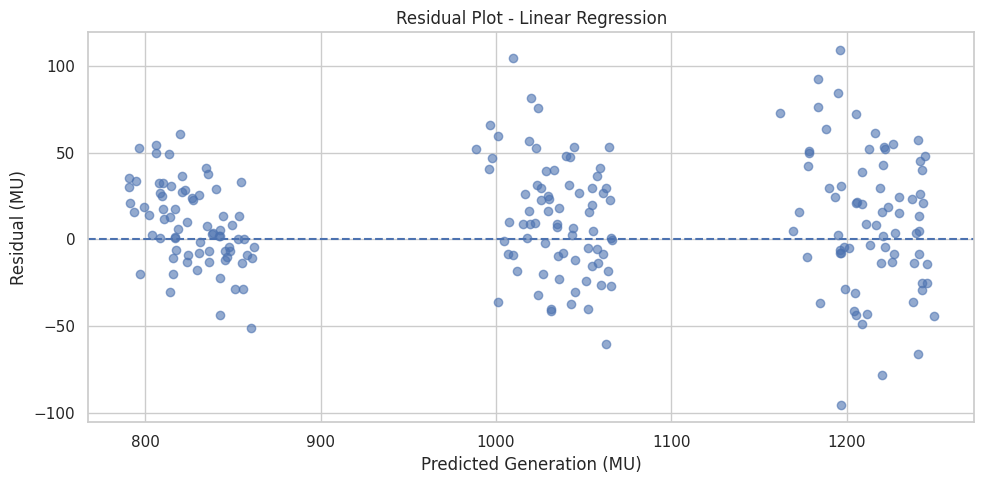

In [ ]:

# ============================================
# STEP 19: RESIDUAL ANALYSIS
# ============================================

residuals = y_test.to_numpy() - sklearn_pred

plt.figure(figsize=(10, 5))

plt.scatter(
    sklearn_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Generation (MU)")
plt.ylabel("Residual (MU)")

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 20: SAVE MODEL
# ============================================

joblib.dump(
    sklearn_model,
    "linear_regression_model.pkl"
)

joblib.dump(
    X_scaler,
    "feature_scaler.pkl"
)

joblib.dump(
    y_scaler,
    "target_scaler.pkl"
)

joblib.dump(
    feature_columns,
    "feature_columns.pkl"
)

print("Model and preprocessing objects saved!")


Model and preprocessing objects saved!


In [ ]:

# ============================================
# TAB 6: ELECTRICITY GENERATION FORECASTING
# STEP 1: PREPARE FORECASTING DATA
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Start from cleaned regional synthetic data
forecast_df = clean_datasets["Regional Synthetic"].copy()

forecast_df["Date"] = pd.to_datetime(
    forecast_df["Date"]
)

forecast_df = forecast_df.sort_values(
    ["Region", "Date"]
).reset_index(drop=True)

# Target variables
target_columns = [
    "Total_Actual_MU",
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU"
]

# Historical features
for col in target_columns:

    grouped = forecast_df.groupby("Region")[col]

    # Lag features
    for lag in [1, 7, 30]:
        forecast_df[f"{col}_Lag_{lag}"] = grouped.shift(lag)

    # Rolling averages: only previous observations
    forecast_df[f"{col}_Rolling_7"] = (
        grouped.transform(
            lambda x: x.shift(1).rolling(7).mean()
        )
    )

    forecast_df[f"{col}_Rolling_30"] = (
        grouped.transform(
            lambda x: x.shift(1).rolling(30).mean()
        )
    )

# Calendar features
forecast_df["Month"] = forecast_df["Date"].dt.month
forecast_df["DayOfWeek"] = forecast_df["Date"].dt.dayofweek
forecast_df["Quarter"] = forecast_df["Date"].dt.quarter
forecast_df["DayOfYear"] = forecast_df["Date"].dt.dayofyear

# Cyclical calendar encoding
forecast_df["Month_Sin"] = np.sin(
    2 * np.pi * forecast_df["Month"] / 12
)

forecast_df["Month_Cos"] = np.cos(
    2 * np.pi * forecast_df["Month"] / 12
)

forecast_df["DayOfWeek_Sin"] = np.sin(
    2 * np.pi * forecast_df["DayOfWeek"] / 7
)

forecast_df["DayOfWeek_Cos"] = np.cos(
    2 * np.pi * forecast_df["DayOfWeek"] / 7
)

# Encode categorical variables
forecast_df = pd.get_dummies(
    forecast_df,
    columns=["Region", "Season"],
    dtype=int
)

# Remove rows without sufficient historical observations
forecast_df = forecast_df.dropna().reset_index(drop=True)

print("Forecasting dataset prepared!")
print("Dataset shape:", forecast_df.shape)

display(forecast_df.head())


Forecasting dataset prepared!
Dataset shape: (1850, 61)


,Date,Data_Source,Year,Month,Day,DayOfWeek,Is_Weekend,Latitude,Longitude,Centroid_Lat,...,DayOfWeek_Cos,Region_Eastern,Region_NorthEastern,Region_Northern,Region_Southern,Region_Western,Season_Monsoon,Season_Post-Monsoon,Season_Summer,Season_Winter
0,2024-01-31,synthetic,2024,1,31,2,0,23.0,86.0,23.2,...,-0.222521,1,0,0,0,0,0,0,0,1
1,2024-02-01,synthetic,2024,2,1,3,0,23.0,86.0,23.2,...,-0.900969,1,0,0,0,0,0,0,0,1
2,2024-02-02,synthetic,2024,2,2,4,0,23.0,86.0,23.2,...,-0.900969,1,0,0,0,0,0,0,0,1
3,2024-02-03,synthetic,2024,2,3,5,1,23.0,86.0,23.2,...,-0.222521,1,0,0,0,0,0,0,0,1
4,2024-02-04,synthetic,2024,2,4,6,1,23.0,86.0,23.2,...,0.623490,1,0,0,0,0,0,0,0,1


In [ ]:

# ============================================
# STEP 2: SELECT FEATURES AND TARGET
# ============================================

target = "Total_Actual_MU"

# Historical lag features
lag_features = [
    col for col in forecast_df.columns
    if "_Lag_" in col
]

# Rolling average features
rolling_features = [
    col for col in forecast_df.columns
    if "_Rolling_" in col
]

# Calendar features
calendar_features = [
    "Month",
    "DayOfWeek",
    "Quarter",
    "DayOfYear",
    "Month_Sin",
    "Month_Cos",
    "DayOfWeek_Sin",
    "DayOfWeek_Cos"
]

# Region and season encoded features
categorical_features = [
    col for col in forecast_df.columns
    if col.startswith("Region_")
    or col.startswith("Season_")
]

feature_columns = (
    lag_features
    + rolling_features
    + calendar_features
    + categorical_features
)

X = forecast_df[feature_columns].copy()
y = forecast_df[target].copy()

print("Input feature count:", len(feature_columns))
print("Input data shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(feature_columns)


Input feature count: 37
Input data shape: (1850, 37)
Target shape: (1850,)

Selected features:
['Total_Actual_MU_Lag_1', 'Total_Actual_MU_Lag_7', 'Total_Actual_MU_Lag_30', 'Thermal_Actual_MU_Lag_1', 'Thermal_Actual_MU_Lag_7', 'Thermal_Actual_MU_Lag_30', 'Nuclear_Actual_MU_Lag_1', 'Nuclear_Actual_MU_Lag_7', 'Nuclear_Actual_MU_Lag_30', 'Hydro_Actual_MU_Lag_1', 'Hydro_Actual_MU_Lag_7', 'Hydro_Actual_MU_Lag_30', 'Total_Actual_MU_Rolling_7', 'Total_Actual_MU_Rolling_30', 'Thermal_Actual_MU_Rolling_7', 'Thermal_Actual_MU_Rolling_30', 'Nuclear_Actual_MU_Rolling_7', 'Nuclear_Actual_MU_Rolling_30', 'Hydro_Actual_MU_Rolling_7', 'Hydro_Actual_MU_Rolling_30', 'Month', 'DayOfWeek', 'Quarter', 'DayOfYear', 'Month_Sin', 'Month_Cos', 'DayOfWeek_Sin', 'DayOfWeek_Cos', 'Region_Eastern', 'Region_NorthEastern', 'Region_Northern', 'Region_Southern', 'Region_Western', 'Season_Monsoon', 'Season_Post-Monsoon', 'Season_Summer', 'Season_Winter']


In [ ]:

# ============================================
# STEP 3: CHRONOLOGICAL DATA SPLITTING
# ============================================

unique_dates = np.sort(
    forecast_df["Date"].unique()
)

n_dates = len(unique_dates)

train_end = int(n_dates * 0.70)
val_end = int(n_dates * 0.85)

train_end_date = unique_dates[train_end]
val_end_date = unique_dates[val_end]

train_mask = forecast_df["Date"] < train_end_date

val_mask = (
    (forecast_df["Date"] >= train_end_date)
    & (forecast_df["Date"] < val_end_date)
)

test_mask = forecast_df["Date"] >= val_end_date

X_train = X.loc[train_mask].copy()
X_val = X.loc[val_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[val_mask].copy()
y_test = y.loc[test_mask].copy()

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(forecast_df.loc[train_mask, "Date"].min(),
      "to",
      forecast_df.loc[train_mask, "Date"].max())

print("\nValidation period:")
print(forecast_df.loc[val_mask, "Date"].min(),
      "to",
      forecast_df.loc[val_mask, "Date"].max())

print("\nTesting period:")
print(forecast_df.loc[test_mask, "Date"].min(),
      "to",
      forecast_df.loc[test_mask, "Date"].max())


Training records: 1295
Validation records: 275
Testing records: 280

Training period:
2024-01-31 00:00:00 to 2024-10-15 00:00:00

Validation period:
2024-10-16 00:00:00 to 2024-12-09 00:00:00

Testing period:
2024-12-10 00:00:00 to 2025-02-03 00:00:00


In [ ]:

# ============================================
# STEP 4: LINEAR REGRESSION
# ============================================

from sklearn.preprocessing import StandardScaler

lr_scaler = StandardScaler()

X_train_lr = lr_scaler.fit_transform(X_train)
X_val_lr = lr_scaler.transform(X_val)

lr_model = LinearRegression()

lr_model.fit(
    X_train_lr,
    y_train
)

lr_predictions = lr_model.predict(X_val_lr)

print("Linear Regression training completed!")
print("First 10 predictions:")
print(lr_predictions[:10])


Linear Regression training completed!
First 10 predictions:
[599.61493083 600.71586013 582.3812569  578.55509095 574.96431373
 599.21188453 602.50045864 609.2438909  591.10252226 592.50513846]


In [ ]:

# ============================================
# STEP 5: RANDOM FOREST REGRESSOR
# ============================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

rf_predictions = rf_model.predict(X_val)

print("Random Forest training completed!")
print("First 10 predictions:")
print(rf_predictions[:10])


Random Forest training completed!
First 10 predictions:
[600.80047265 601.78178914 584.48790518 593.10509223 594.30117344
 607.91638069 603.26558889 607.98353794 598.10500231 601.45841288]


In [ ]:

# ============================================
# STEP 6: INSTALL XGBOOST
# ============================================

%pip -q install xgboost


In [ ]:

# ============================================
# STEP 7: XGBOOST REGRESSOR
# ============================================

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train,
    verbose=False
)

xgb_predictions = xgb_model.predict(X_val)

print("XGBoost training completed!")
print("First 10 predictions:")
print(xgb_predictions[:10])


XGBoost training completed!
First 10 predictions:
[606.43097 606.6512  587.4941  588.3801  580.9629  607.84937 608.1186
 612.30524 601.7633  593.163  ]


In [ ]:

# ============================================
# STEP 8: HIST GRADIENT BOOSTING
# ============================================

hist_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

hist_model.fit(
    X_train,
    y_train
)

hist_predictions = hist_model.predict(X_val)

print("HistGradientBoosting training completed!")
print("First 10 predictions:")
print(hist_predictions[:10])


HistGradientBoosting training completed!
First 10 predictions:
[602.29979024 603.99868265 583.1561391  581.53908174 576.53116374
 603.51558511 603.07464133 605.49461706 593.48074558 593.05397623]


In [ ]:

# ============================================
# STEP 9: SARIMAX
# ============================================

%pip -q install statsmodels

from statsmodels.tsa.statespace.sarimax import SARIMAX

print("SARIMAX imported successfully!")


SARIMAX imported successfully!


In [ ]:

# ============================================
# STEP 10: SARIMAX REGIONAL FORECASTING
# ============================================

sarimax_predictions = []

regions_list = sorted(
    forecast_df["Region_Northern"].columns
) if False else [
    "Northern",
    "Western",
    "Southern",
    "Eastern",
    "NorthEastern"
]

for region in regions_list:

    print("Training SARIMAX:", region)

    # Recover the original region's observations
    # from the encoded columns
    region_col = "Region_" + region

    region_data = forecast_df[
        forecast_df[region_col] == 1
    ].sort_values("Date")

    train_region = region_data[
        region_data["Date"] < train_end_date
    ]

    val_region = region_data[
        (region_data["Date"] >= train_end_date)
        & (region_data["Date"] < val_end_date)
    ]

    model = SARIMAX(
        train_region[target].to_numpy(),
        order=(1, 1, 1),
        seasonal_order=(1, 0, 1, 7),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted_model = model.fit(disp=False, maxiter=100)

    predictions = fitted_model.forecast(
        steps=len(val_region)
    )

    for date, actual, prediction in zip(
        val_region["Date"],
        val_region[target],
        predictions
    ):

        sarimax_predictions.append({
            "Date": date,
            "Region": region,
            "Actual": actual,
            "Predicted": prediction
        })

sarimax_results = pd.DataFrame(sarimax_predictions)

print("\nSARIMAX forecasting completed!")

display(sarimax_results.head())


Training SARIMAX: Northern
Training SARIMAX: Western
Training SARIMAX: Southern
Training SARIMAX: Eastern
Training SARIMAX: NorthEastern

SARIMAX forecasting completed!


,Date,Region,Actual,Predicted
0,2024-10-16,Northern,824.006058,804.144480
1,2024-10-17,Northern,792.543822,809.786016
2,2024-10-18,Northern,815.615351,806.029994
3,2024-10-19,Northern,835.334779,811.760425
4,2024-10-20,Northern,818.921872,806.328102


In [ ]:
# ============================================
# STEP 11: MODEL COMPARISON
# ============================================

def calculate_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
    ) * 100

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "WAPE_Percent": wape
    }


# Ordinary ML model predictions
model_predictions = {
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "HistGradientBoosting": hist_predictions
}

comparison_results = []

for name, predictions in model_predictions.items():

    metrics = calculate_metrics(
        y_val,
        predictions
    )

    metrics["Model"] = name

    comparison_results.append(metrics)


# Reconstruct 'Region' from the one-hot encoded columns for the validation set
region_cols = [col for col in forecast_df.columns if col.startswith("Region_")]
val_df_with_region = forecast_df.loc[val_mask].copy()
# Find which one-hot column is 1 for each row and extract the region name
val_df_with_region["Region"] = val_df_with_region[region_cols].idxmax(axis=1).str.replace("Region_", "")

# Match SARIMAX forecasts with the validation records
sarimax_aligned = (
    val_df_with_region[
        ["Date", "Region", target]
    ].merge(
        sarimax_results[
            ["Date", "Region", "Predicted"]
        ],
        on=["Date", "Region"],
        how="inner",
        validate="one_to_one"
    )
)

sarimax_pred = np.maximum(
    sarimax_aligned["Predicted"].to_numpy(),
    0
)

sarimax_actual = sarimax_aligned[target].to_numpy()

sarimax_metrics = calculate_metrics(
    sarimax_actual,
    sarimax_pred
)

sarimax_metrics["Model"] = "SARIMAX"

comparison_results.append(sarimax_metrics)


# Final comparison table
model_comparison = pd.DataFrame(
    comparison_results
).set_index("Model")

model_comparison = model_comparison.sort_values(
    "RMSE"
)

display(model_comparison.round(4))

,MAE,MSE,RMSE,R2,WAPE_Percent
Model,,,,,
XGBoost,21.3199,842.1934,29.0206,0.9942,2.8076
HistGradientBoosting,21.3465,880.9012,29.6800,0.9939,2.8111
Random Forest,21.8793,920.1035,30.3332,0.9936,2.8813
SARIMAX,22.8094,955.7131,30.9146,0.9934,3.0038
Linear Regression,28.1292,1298.5451,36.0353,0.9910,3.7043


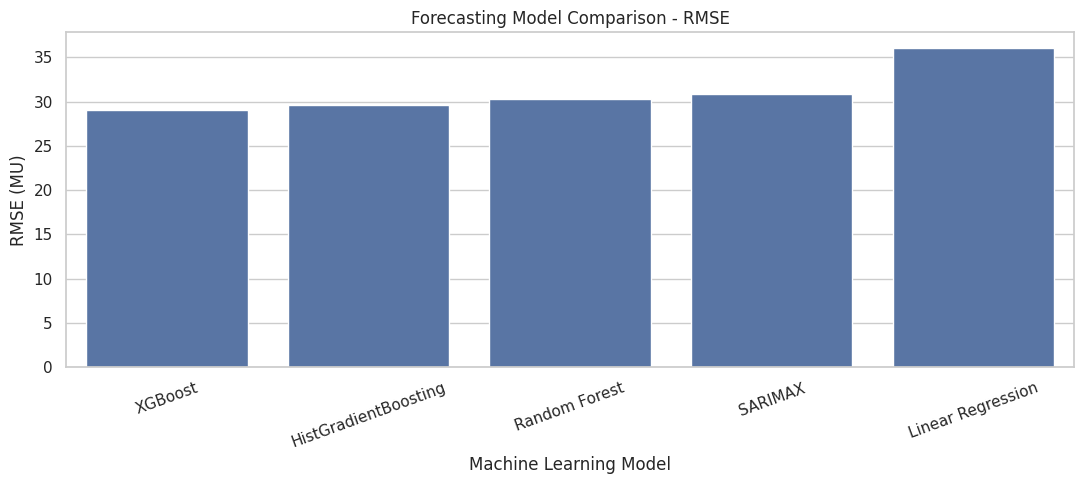

In [ ]:

# ============================================
# STEP 12: MODEL PERFORMANCE VISUALIZATION
# ============================================

plt.figure(figsize=(11, 5))

sns.barplot(
    x=model_comparison.index,
    y=model_comparison["RMSE"]
)

plt.title("Forecasting Model Comparison - RMSE")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (MU)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


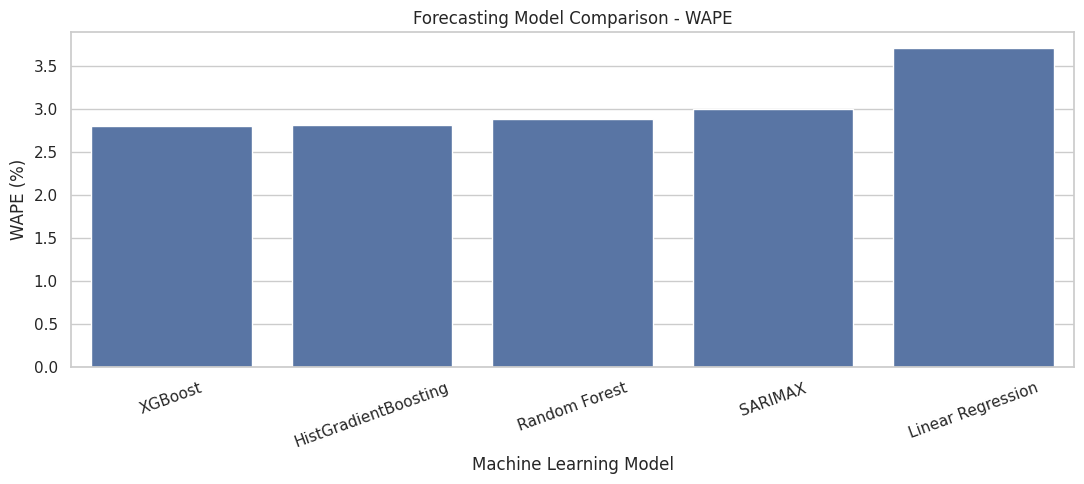

In [ ]:

# ============================================
# STEP 13: WAPE COMPARISON
# ============================================

plt.figure(figsize=(11, 5))

sns.barplot(
    x=model_comparison.index,
    y=model_comparison["WAPE_Percent"]
)

plt.title("Forecasting Model Comparison - WAPE")
plt.xlabel("Machine Learning Model")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 14: SELECT BEST VALIDATION MODEL
# ============================================

best_model_name = model_comparison["RMSE"].idxmin()

print("Best model based on validation RMSE:")
print(best_model_name)

prediction_lookup = {
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions,
    "HistGradientBoosting": hist_predictions
}

if best_model_name == "SARIMAX":
    best_predictions = sarimax_pred
    best_actual = sarimax_actual
else:
    best_predictions = prediction_lookup[best_model_name]
    best_actual = y_val.to_numpy()

print("\nSelected model:", best_model_name)


Best model based on validation RMSE:
XGBoost

Selected model: XGBoost


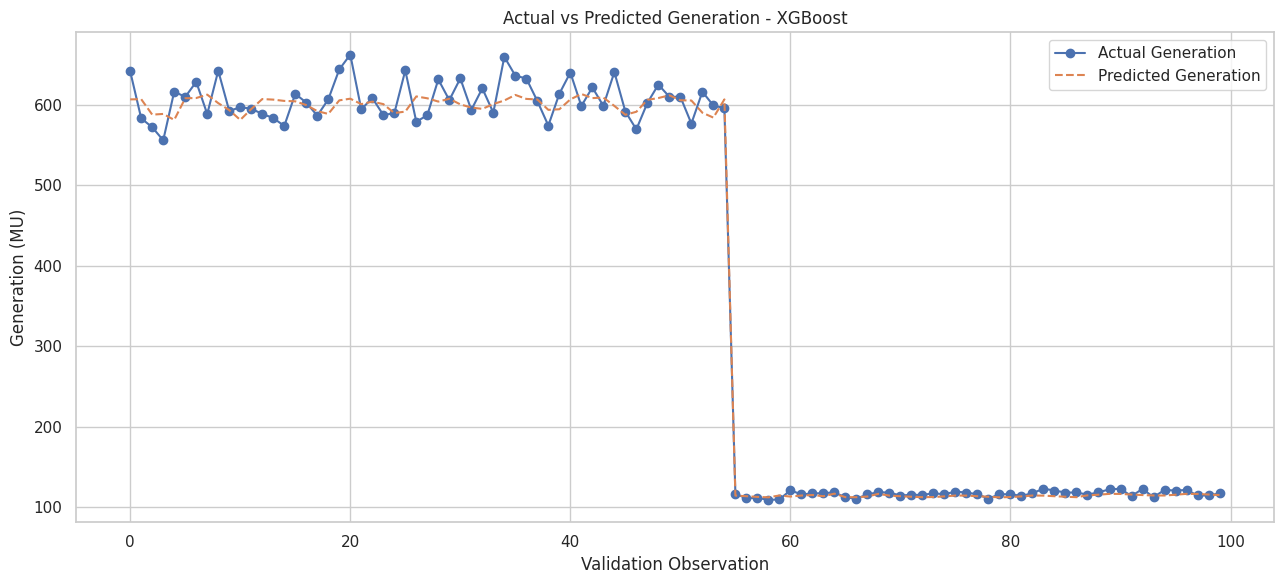

In [ ]:

# ============================================
# STEP 15: ACTUAL VS PREDICTED GENERATION
# ============================================

plt.figure(figsize=(13, 6))

plt.plot(
    best_actual[:100],
    label="Actual Generation",
    marker="o"
)

plt.plot(
    best_predictions[:100],
    label="Predicted Generation",
    linestyle="--"
)

plt.title(
    f"Actual vs Predicted Generation - {best_model_name}"
)

plt.xlabel("Validation Observation")
plt.ylabel("Generation (MU)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

# ============================================
# STEP 16: INDIVIDUAL ENERGY SOURCE FORECASTING
# ============================================

source_targets = [
    "Thermal_Actual_MU",
    "Nuclear_Actual_MU",
    "Hydro_Actual_MU"
]

source_results = []
source_best_models = {}

for source in source_targets:

    print("\nTraining models for:", source)

    y_train_source = forecast_df.loc[
        train_mask, source
    ]

    y_val_source = forecast_df.loc[
        val_mask, source
    ]

    # Linear Regression
    lr_source = LinearRegression()

    lr_source.fit(
        X_train_lr,
        y_train_source
    )

    lr_source_pred = lr_source.predict(X_val_lr)

    # Random Forest
    rf_source = RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    rf_source.fit(X_train, y_train_source)

    rf_source_pred = rf_source.predict(X_val)

    # XGBoost
    xgb_source = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    xgb_source.fit(X_train, y_train_source)

    xgb_source_pred = xgb_source.predict(X_val)

    # HistGradientBoosting
    hist_source = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )

    hist_source.fit(X_train, y_train_source)

    hist_source_pred = hist_source.predict(X_val)

    predictions = {
        "Linear Regression": lr_source_pred,
        "Random Forest": rf_source_pred,
        "XGBoost": xgb_source_pred,
        "HistGradientBoosting": hist_source_pred
    }

    for model_name, pred in predictions.items():

        metrics = calculate_metrics(
            y_val_source,
            pred
        )

        source_results.append({
            "Energy_Source": source,
            "Model": model_name,
            **metrics
        })

    # Select best model for this energy source
    best_name = min(
        predictions,
        key=lambda name: calculate_metrics(
            y_val_source,
            predictions[name]
        )["RMSE"]
    )

    source_best_models[source] = {
        "model_name": best_name,
        "model": {
            "Linear Regression": lr_source,
            "Random Forest": rf_source,
            "XGBoost": xgb_source,
            "HistGradientBoosting": hist_source
        }[best_name]
    }

    print("Best model:", best_name)


source_comparison = pd.DataFrame(source_results)

display(
    source_comparison.sort_values(
        ["Energy_Source", "RMSE"]
    ).round(4)
)



Training models for: Thermal_Actual_MU
Best model: HistGradientBoosting

Training models for: Nuclear_Actual_MU
Best model: Random Forest

Training models for: Hydro_Actual_MU
Best model: HistGradientBoosting


,Energy_Source,Model,MAE,MSE,RMSE,R2,WAPE_Percent
11,Hydro_Actual_MU,HistGradientBoosting,5.5833,60.9853,7.8093,0.9831,4.9878
10,Hydro_Actual_MU,XGBoost,5.6588,63.1881,7.9491,0.9825,5.0552
8,Hydro_Actual_MU,Linear Regression,6.8578,68.6956,8.2883,0.9810,6.1264
9,Hydro_Actual_MU,Random Forest,6.0526,72.5981,8.5204,0.9799,5.4070
5,Nuclear_Actual_MU,Random Forest,0.2436,0.1554,0.3942,0.9997,0.9545
7,Nuclear_Actual_MU,HistGradientBoosting,0.2430,0.1658,0.4072,0.9996,0.9522
6,Nuclear_Actual_MU,XGBoost,0.2523,0.1663,0.4078,0.9996,0.9886
4,Nuclear_Actual_MU,Linear Regression,0.4018,0.2619,0.5117,0.9994,1.5745
3,Thermal_Actual_MU,HistGradientBoosting,20.6717,807.6421,28.4190,0.9923,3.3240
2,Thermal_Actual_MU,XGBoost,21.1764,823.5439,28.6975,0.9921,3.4051


In [ ]:

# ============================================
# STEP 17: BEST MODEL BY ENERGY SOURCE
# ============================================

best_source_summary = (
    source_comparison
    .sort_values("RMSE")
    .groupby("Energy_Source")
    .first()
    .reset_index()
)

display(
    best_source_summary[
        [
            "Energy_Source",
            "Model",
            "MAE",
            "RMSE",
            "R2",
            "WAPE_Percent"
        ]
    ].round(4)
)


,Energy_Source,Model,MAE,RMSE,R2,WAPE_Percent
0,Hydro_Actual_MU,HistGradientBoosting,5.5833,7.8093,0.9831,4.9878
1,Nuclear_Actual_MU,Random Forest,0.2436,0.3942,0.9997,0.9545
2,Thermal_Actual_MU,HistGradientBoosting,20.6717,28.4190,0.9923,3.3240


In [ ]:

# ============================================
# STEP 18: REGIONAL VALIDATION PERFORMANCE
# ============================================

if best_model_name == "SARIMAX":

    regional_predictions = sarimax_aligned.copy()

    regional_predictions["Predicted"] = sarimax_pred

else:

    regional_predictions = forecast_df.loc[
        val_mask,
        ["Date", target]
    ].copy()

    regional_predictions["Region"] = (
        forecast_df.loc[val_mask, "Region_" .__str__() + "Northern"].map(
            {1: "Northern", 0: "Other"}
        ) if False else
        forecast_df.loc[val_mask, "Region_Northern"].map(
            {1: "Northern"}
        )
    )

    # Recover the region using encoded columns
    region_encoding = [
        col for col in forecast_df.columns
        if col.startswith("Region_")
    ]

    regional_predictions["Region"] = (
        forecast_df.loc[val_mask, region_encoding]
        .idxmax(axis=1)
        .str.replace("Region_", "", regex=False)
        .to_numpy()
    )

    regional_predictions["Predicted"] = best_predictions


regional_error_summary = []

for region, group in regional_predictions.groupby("Region"):

    metrics = calculate_metrics(
        group["Actual"] if "Actual" in group.columns else group[target],
        group["Predicted"]
    )

    metrics["Region"] = region

    regional_error_summary.append(metrics)


regional_performance = pd.DataFrame(
    regional_error_summary
).set_index("Region")

display(regional_performance.round(4))


,MAE,MSE,RMSE,R2,WAPE_Percent
Region,,,,,
Eastern,19.3922,576.4135,24.0086,-0.0088,3.1983
NorthEastern,3.4839,16.2912,4.0362,-0.3390,2.9835
Northern,19.9605,644.1019,25.3792,-0.2690,2.4106
Southern,29.0250,1187.7155,34.4632,0.0301,2.7930
Western,34.7380,1786.4449,42.2664,0.0687,2.8794


In [ ]:

# ============================================
# STEP 19: EXPORT VALIDATION RESULTS
# ============================================

if best_model_name == "SARIMAX":

    validation_output = sarimax_aligned.copy()

    validation_output = validation_output.rename(
        columns={
            "Actual": "Actual_Generation_MU",
            "Predicted": "Predicted_Generation_MU"
        }
    )

else:

    validation_output = forecast_df.loc[
        val_mask,
        ["Date", target]
    ].copy()

    validation_output["Predicted_Generation_MU"] = (
        best_predictions
    )

    validation_output = validation_output.rename(
        columns={
            target: "Actual_Generation_MU"
        }
    )

    region_encoding = [
        col for col in forecast_df.columns
        if col.startswith("Region_")
    ]

    validation_output["Region"] = (
        forecast_df.loc[val_mask, region_encoding]
        .idxmax(axis=1)
        .str.replace("Region_", "", regex=False)
        .to_numpy()
    )


validation_output.to_csv(
    "generation_validation_predictions.csv",
    index=False
)

model_comparison.to_csv(
    "total_generation_model_comparison.csv"
)

source_comparison.to_csv(
    "energy_source_model_comparison.csv",
    index=False
)

regional_performance.to_csv(
    "regional_validation_performance.csv"
)

print("Forecasting results exported successfully!")


Forecasting results exported successfully!


In [ ]:

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Keep only the training-period observations
train_rows = forecast_df.loc[train_mask].copy()

X_train_tune = X.loc[train_mask].copy()
y_train_tune = y.loc[train_mask].copy()

# Split by unique dates, not by individual rows
training_dates = np.array(sorted(train_rows["Date"].unique()))

tscv = TimeSeriesSplit(n_splits=4)

cv_splits = []

for fold_train_idx, fold_val_idx in tscv.split(training_dates):
    fold_train_dates = training_dates[fold_train_idx]
    fold_val_dates = training_dates[fold_val_idx]

    train_positions = np.flatnonzero(
        train_rows["Date"].isin(fold_train_dates).to_numpy()
    )

    val_positions = np.flatnonzero(
        train_rows["Date"].isin(fold_val_dates).to_numpy()
    )

    cv_splits.append((train_positions, val_positions))

print("Number of chronological folds:", len(cv_splits))

for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: "
        f"{len(train_idx)} training rows, "
        f"{len(val_idx)} validation rows"
    )


Number of chronological folds: 4
Fold 1: 275 training rows, 255 validation rows
Fold 2: 530 training rows, 255 validation rows
Fold 3: 785 training rows, 255 validation rows
Fold 4: 1040 training rows, 255 validation rows


In [ ]:

rf_parameter_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=rf_parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_tune, y_train_tune)

best_rf = rf_grid.best_estimator_

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best cross-validation RMSE:", -rf_grid.best_score_)


Fitting 4 folds for each of 24 candidates, totalling 96 fits
Best Random Forest parameters:
{'max_depth': 12, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validation RMSE: 33.03203124496872


In [ ]:

xgb_parameter_grid = {
    "n_estimators": [150, 300],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ),
    param_grid=xgb_parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train_tune, y_train_tune)

best_xgb = xgb_grid.best_estimator_

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)
print("Best cross-validation RMSE:", -xgb_grid.best_score_)


Fitting 4 folds for each of 36 candidates, totalling 144 fits
Best XGBoost parameters:
{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 150, 'subsample': 0.8}
Best cross-validation RMSE: 36.60600345090415


In [ ]:

hgb_parameter_grid = {
    "max_iter": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_leaf_nodes": [10, 15, 20],
    "l2_regularization": [0.0, 1.0]
}

hgb_grid = GridSearchCV(
    estimator=HistGradientBoostingRegressor(
        random_state=42
    ),
    param_grid=hgb_parameter_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

hgb_grid.fit(X_train_tune, y_train_tune)

best_hgb = hgb_grid.best_estimator_

print("Best HistGradientBoosting parameters:")
print(hgb_grid.best_params_)
print("Best cross-validation RMSE:", -hgb_grid.best_score_)


Fitting 4 folds for each of 54 candidates, totalling 216 fits
Best HistGradientBoosting parameters:
{'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 10}
Best cross-validation RMSE: 32.766226971713444


In [ ]:

tuned_models = {
    "Linear Regression": lr_model,
    "Tuned Random Forest": best_rf,
    "Tuned XGBoost": best_xgb,
    "Tuned HistGradientBoosting": best_hgb
}

tuned_predictions = {}
tuned_results = []

for model_name, model in tuned_models.items():

    if model_name == "Linear Regression":
        predictions = model.predict(X_val_lr)
    else:
        predictions = model.predict(X_val)

    tuned_predictions[model_name] = predictions

    metrics = calculate_metrics(y_val, predictions)
    metrics["Model"] = model_name

    tuned_results.append(metrics)

tuned_comparison = pd.DataFrame(tuned_results)
tuned_comparison = tuned_comparison.sort_values("RMSE").reset_index(drop=True)

display(tuned_comparison)


,MAE,MSE,RMSE,R2,WAPE_Percent,Model
0,20.787357,859.765550,29.321759,0.994058,2.737495,Tuned HistGradientBoosting
1,22.178035,912.841230,30.213262,0.993691,2.920634,Tuned XGBoost
2,21.879296,920.103546,30.333209,0.993641,2.881293,Tuned Random Forest
3,28.129207,1298.545125,36.035332,0.991026,3.704346,Linear Regression


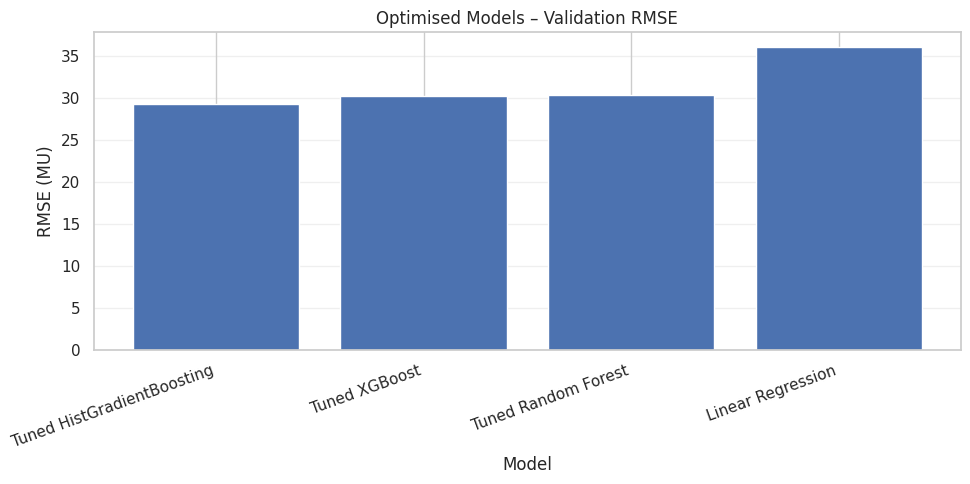

In [ ]:

plt.figure(figsize=(10, 5))

plt.bar(
    tuned_comparison["Model"],
    tuned_comparison["RMSE"]
)

plt.title("Optimised Models – Validation RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE (MU)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

best_tuned_model_name = tuned_comparison.iloc[0]["Model"]

best_tuned_model = tuned_models[best_tuned_model_name]
best_tuned_predictions = tuned_predictions[best_tuned_model_name]

print("Best optimised model:", best_tuned_model_name)
print("Validation performance:")

display(
    tuned_comparison[
        tuned_comparison["Model"] == best_tuned_model_name
    ]
)


Best optimised model: Tuned HistGradientBoosting
Validation performance:


,MAE,MSE,RMSE,R2,WAPE_Percent,Model
0,20.787357,859.76555,29.321759,0.994058,2.737495,Tuned HistGradientBoosting


In [ ]:

# Save the model comparison and best parameter configurations
tuning_summary = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Best Parameters": str(rf_grid.best_params_),
        "CV RMSE": -rf_grid.best_score_
    },
    {
        "Model": "XGBoost",
        "Best Parameters": str(xgb_grid.best_params_),
        "CV RMSE": -xgb_grid.best_score_
    },
    {
        "Model": "HistGradientBoosting",
        "Best Parameters": str(hgb_grid.best_params_),
        "CV RMSE": -hgb_grid.best_score_
    }
])

tuned_comparison.to_csv(
    "optimised_model_validation_comparison.csv",
    index=False
)

tuning_summary.to_csv(
    "model_hyperparameter_tuning_summary.csv",
    index=False
)

print("Optimisation results saved successfully.")
display(tuning_summary)


Optimisation results saved successfully.


,Model,Best Parameters,CV RMSE
0,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 2, 'min_...",33.032031
1,XGBoost,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",36.606003
2,HistGradientBoosting,"{'l2_regularization': 0.0, 'learning_rate': 0....",32.766227


In [ ]:

# Prepare the untouched test data
X_test_eval = X.loc[test_mask].copy()
y_test_eval = y.loc[test_mask].copy()

test_dates = forecast_df.loc[test_mask, "Date"].copy()

print("Test dataset shape:", X_test_eval.shape)
print("Test target shape:", y_test_eval.shape)

print(
    "Test period:",
    test_dates.min().date(),
    "to",
    test_dates.max().date()
)


Test dataset shape: (280, 37)
Test target shape: (280,)
Test period: 2024-12-10 to 2025-02-03


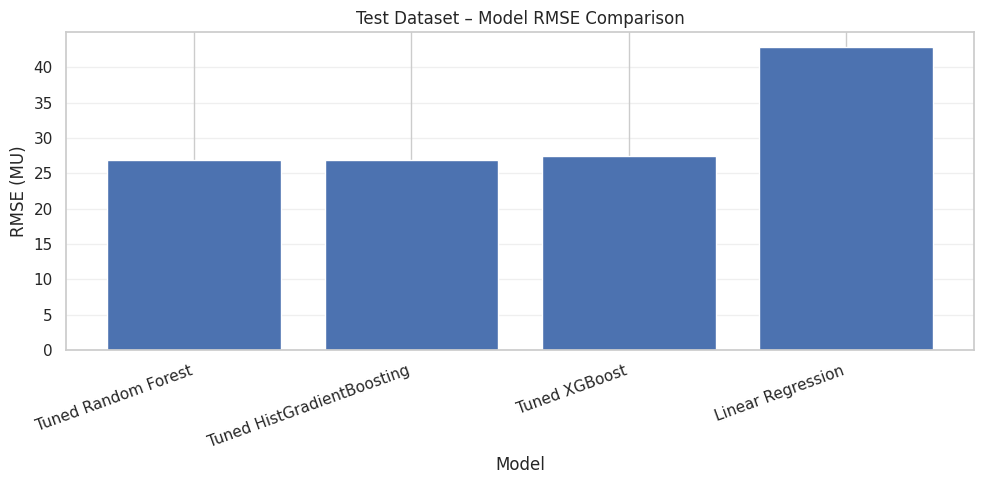

In [ ]:
test_predictions = {}
test_results = []

for model_name, model in tuned_models.items():
    if model_name == "Linear Regression":
        predictions = model.predict(lr_scaler.transform(X_test_eval))
    else:
        predictions = model.predict(X_test_eval)

    test_predictions[model_name] = predictions

    metrics = calculate_metrics(y_test_eval, predictions)
    metrics["Model"] = model_name
    test_results.append(metrics)

test_comparison = pd.DataFrame(test_results)
test_comparison = test_comparison.sort_values("RMSE").reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.bar(
    test_comparison["Model"],
    test_comparison["RMSE"]
)
plt.title("Test Dataset – Model RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (MU)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

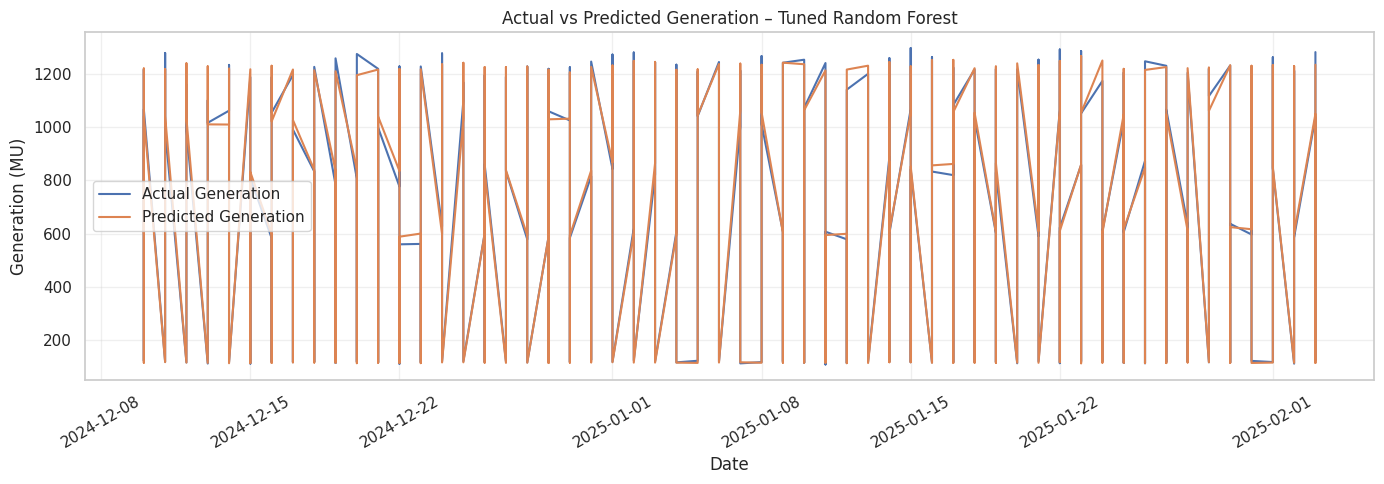

Best model on test data: Tuned Random Forest


In [ ]:

best_test_model_name = test_comparison.iloc[0]["Model"]

best_test_predictions = test_predictions[
    best_test_model_name
]

comparison_df = pd.DataFrame({
    "Date": test_dates.to_numpy(),
    "Actual": y_test_eval.to_numpy(),
    "Predicted": best_test_predictions
})

comparison_df = comparison_df.sort_values("Date")

plt.figure(figsize=(14, 5))

plt.plot(
    comparison_df["Date"],
    comparison_df["Actual"],
    label="Actual Generation"
)

plt.plot(
    comparison_df["Date"],
    comparison_df["Predicted"],
    label="Predicted Generation"
)

plt.title(
    f"Actual vs Predicted Generation – {best_test_model_name}"
)

plt.xlabel("Date")
plt.ylabel("Generation (MU)")
plt.legend()
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Best model on test data:", best_test_model_name)


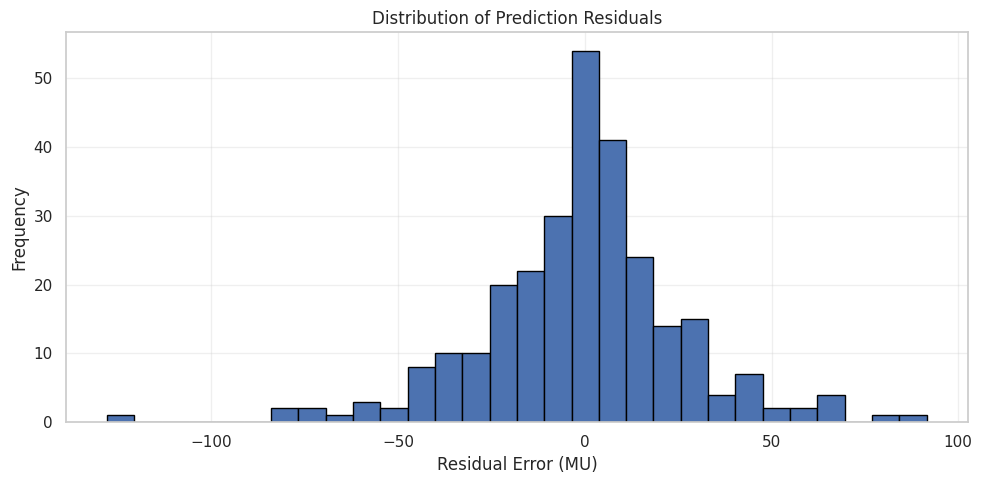

In [ ]:

comparison_df["Residual"] = (
    comparison_df["Actual"] -
    comparison_df["Predicted"]
)

plt.figure(figsize=(10, 5))

plt.hist(
    comparison_df["Residual"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual Error (MU)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


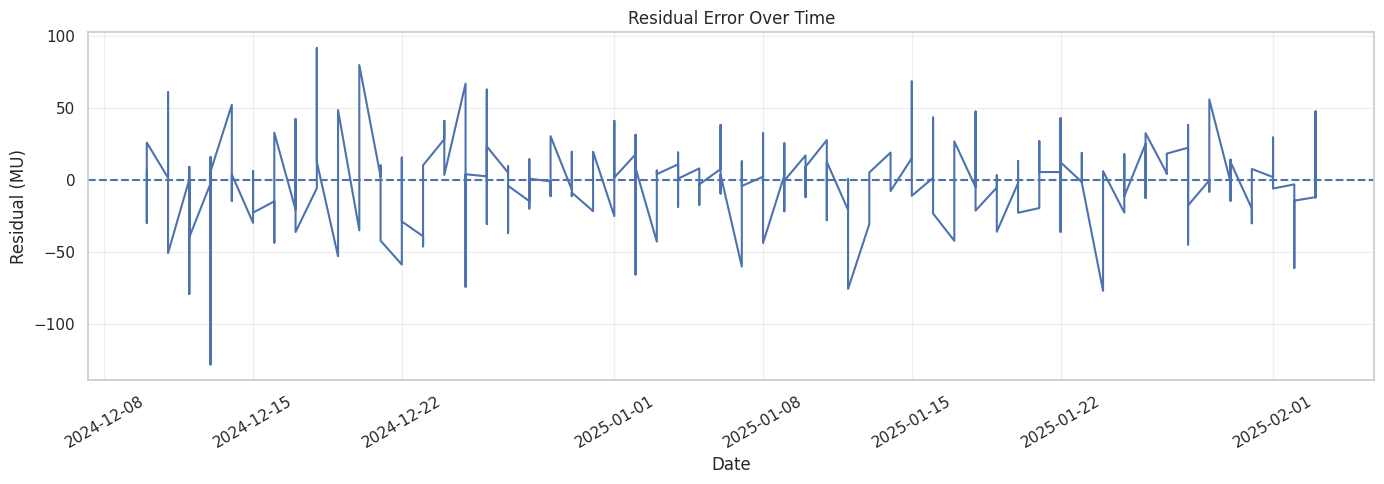

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(
    comparison_df["Date"],
    comparison_df["Residual"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Residual Error Over Time")
plt.xlabel("Date")
plt.ylabel("Residual (MU)")
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

region_columns = [
    col for col in forecast_df.columns
    if col.startswith("Region_")
]

test_region_data = forecast_df.loc[
    test_mask,
    region_columns + ["Date", target]
].copy()

test_region_data["Region"] = (
    test_region_data[region_columns]
    .idxmax(axis=1)
    .str.replace("Region_", "", regex=False)
)

test_region_data["Predicted"] = best_test_predictions

regional_test_results = []

for region, group in test_region_data.groupby("Region"):

    metrics = calculate_metrics(
        group[target],
        group["Predicted"]
    )

    metrics["Region"] = region

    regional_test_results.append(metrics)

regional_test_comparison = pd.DataFrame(
    regional_test_results
)

regional_test_comparison = regional_test_comparison.sort_values(
    "RMSE"
)

display(regional_test_comparison)


,MAE,MSE,RMSE,R2,WAPE_Percent,Region
1,3.374652,16.810262,4.100032,-0.523478,2.907582,NorthEastern
0,14.757536,363.007732,19.052762,0.102342,2.442041,Eastern
2,22.539107,721.105460,26.853407,-0.299158,2.689541,Northern
3,25.501698,1042.047572,32.280762,0.000232,2.432278,Southern
4,28.366404,1462.705255,38.245330,-0.006425,2.306847,Western


In [ ]:

test_comparison.to_csv(
    "final_test_model_comparison.csv",
    index=False
)

comparison_df.to_csv(
    "best_model_test_predictions.csv",
    index=False
)

regional_test_comparison.to_csv(
    "regional_test_performance.csv",
    index=False
)

print("Tab 8 evaluation results saved successfully.")


Tab 8 evaluation results saved successfully.


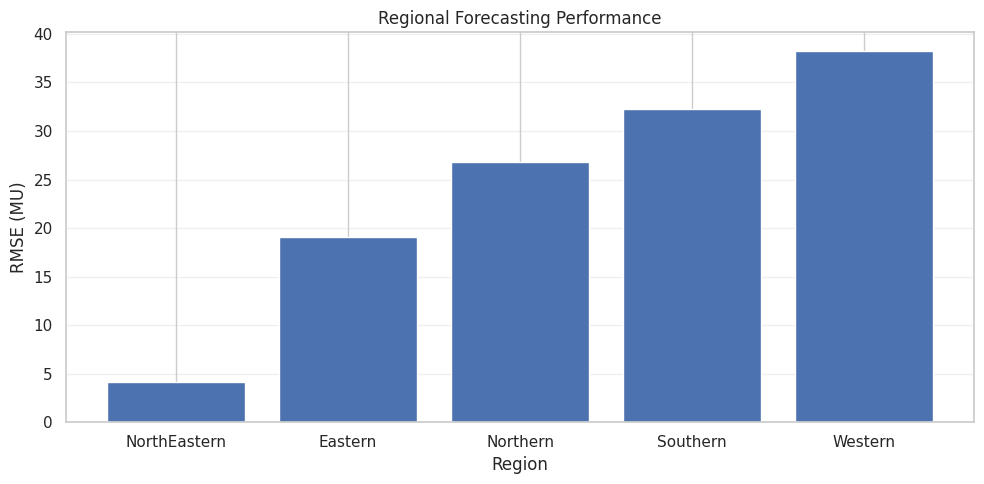

In [ ]:

plt.figure(figsize=(10, 5))

plt.bar(
    regional_test_comparison["Region"],
    regional_test_comparison["RMSE"]
)

plt.title("Regional Forecasting Performance")
plt.xlabel("Region")
plt.ylabel("RMSE (MU)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

test_comparison.to_csv(
    "final_test_model_comparison.csv",
    index=False
)

comparison_df.to_csv(
    "best_model_test_predictions.csv",
    index=False
)

regional_test_comparison.to_csv(
    "regional_test_performance.csv",
    index=False
)

print("Tab 8 evaluation results saved successfully.")


Tab 8 evaluation results saved successfully.


In [ ]:

!pip -q install streamlit plotly pandas pyngrok


In [ ]:

%%writefile app.py

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(
    page_title="India National Grid Analytics",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ India National Grid Energy Analytics")
st.caption("Academic Project | Synthetic Data Only")

# Load the datasets
@st.cache_data
def load_data():
    regional = pd.read_csv("india_power_regional_synthetic_2000.csv")
    overall = pd.read_csv("india_power_overall_synthetic_2000.csv")
    ml_data = pd.read_csv("india_power_synthetic_2000.csv")

    regional["Date"] = pd.to_datetime(regional["Date"])
    overall["Date"] = pd.to_datetime(overall["Date"])
    ml_data["Date"] = pd.to_datetime(ml_data["Date"])

    return regional, overall, ml_data

try:
    regional, overall, ml_data = load_data()
except FileNotFoundError:
    st.error("Please upload all three CSV datasets into the Colab session.")
    st.stop()

# Sidebar filters
st.sidebar.title("Dashboard Filters")

regions = sorted(regional["Region"].unique())

selected_regions = st.sidebar.multiselect(
    "Select Regions",
    regions,
    default=regions
)

filtered = regional[
    regional["Region"].isin(selected_regions)
].copy()

if filtered.empty:
    st.warning("Please select at least one region.")
    st.stop()

# Tabs
tab1, tab2, tab3, tab4, tab5, tab6 = st.tabs([
    "National Overview",
    "Regional Analysis",
    "Energy Sources",
    "Generation Trends",
    "ML Forecasting",
    "Dataset Information"
])

# TAB 1
with tab1:
    st.header("National Grid Overview")

    total = filtered["Total_Actual_MU"].sum()
    thermal = filtered["Thermal_Actual_MU"].sum()
    hydro = filtered["Hydro_Actual_MU"].sum()
    nuclear = filtered["Nuclear_Actual_MU"].sum()

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Total Generation", f"{total:,.2f} MU")
    c2.metric("Thermal Generation", f"{thermal:,.2f} MU")
    c3.metric("Hydro Generation", f"{hydro:,.2f} MU")
    c4.metric("Nuclear Generation", f"{nuclear:,.2f} MU")

    daily = filtered.groupby(
        "Date", as_index=False
    )["Total_Actual_MU"].sum()

    fig = px.line(
        daily,
        x="Date",
        y="Total_Actual_MU",
        title="Daily Electricity Generation"
    )

    st.plotly_chart(fig, use_container_width=True)

# TAB 2
with tab2:
    st.header("Regional Generation Analysis")

    region_data = filtered.groupby(
        "Region", as_index=False
    )["Total_Actual_MU"].sum()

    fig = px.bar(
        region_data,
        x="Region",
        y="Total_Actual_MU",
        color="Region",
        title="Generation by Region"
    )

    st.plotly_chart(fig, use_container_width=True)

    fig = px.box(
        filtered,
        x="Region",
        y="Total_Actual_MU",
        color="Region",
        title="Regional Generation Distribution"
    )

    st.plotly_chart(fig, use_container_width=True)

# TAB 3
with tab3:
    st.header("Energy Source Analysis")

    source_data = pd.DataFrame({
        "Energy Source": ["Thermal", "Hydro", "Nuclear"],
        "Generation": [thermal, hydro, nuclear]
    })

    fig = px.pie(
        source_data,
        names="Energy Source",
        values="Generation",
        hole=0.4,
        title="Energy Source Contribution"
    )

    st.plotly_chart(fig, use_container_width=True)

    source_region = filtered.groupby(
        "Region", as_index=False
    )[[
        "Thermal_Actual_MU",
        "Hydro_Actual_MU",
        "Nuclear_Actual_MU"
    ]].sum()

    source_long = source_region.melt(
        id_vars="Region",
        var_name="Source",
        value_name="Generation"
    )

    source_long["Source"] = source_long["Source"].str.replace(
        "_Actual_MU", "", regex=False
    )

    fig = px.bar(
        source_long,
        x="Region",
        y="Generation",
        color="Source",
        barmode="stack",
        title="Regional Energy Mix"
    )

    st.plotly_chart(fig, use_container_width=True)

# TAB 4
with tab4:
    st.header("Generation Trends")

    filtered["Month"] = filtered["Date"].dt.month

    monthly = filtered.groupby(
        "Month", as_index=False
    )["Total_Actual_MU"].mean()

    fig = px.line(
        monthly,
        x="Month",
        y="Total_Actual_MU",
        markers=True,
        title="Average Monthly Generation"
    )

    st.plotly_chart(fig, use_container_width=True)

    seasonal = filtered.groupby(
        "Season", as_index=False
    )["Total_Actual_MU"].mean()

    fig = px.bar(
        seasonal,
        x="Season",
        y="Total_Actual_MU",
        title="Seasonal Average Generation"
    )

    st.plotly_chart(fig, use_container_width=True)

# TAB 5
with tab5:
    st.header("Machine Learning Forecasting")

    st.info(
        "Upload the test prediction CSV generated in Tab 8 "
        "to display actual versus predicted generation."
    )

    prediction_file = st.file_uploader(
        "Upload best_model_test_predictions.csv",
        type=["csv"]
    )

    if prediction_file is not None:
        predictions = pd.read_csv(prediction_file)

        if {"Actual", "Predicted"}.issubset(predictions.columns):
            fig = px.line(
                predictions,
                y=["Actual", "Predicted"],
                title="Actual vs Predicted Generation"
            )

            st.plotly_chart(fig, use_container_width=True)
            st.dataframe(predictions.head(20))
        else:
            st.warning(
                "CSV must contain Actual and Predicted columns."
            )

# TAB 6
with tab6:
    st.header("Dataset Information")

    st.subheader("Regional Dataset")
    st.write("Shape:", regional.shape)
    st.dataframe(regional.head(10))

    st.subheader("All India Dataset")
    st.write("Shape:", overall.shape)
    st.dataframe(overall.head(10))

    st.subheader("Independent ML Dataset")
    st.write("Shape:", ml_data.shape)
    st.dataframe(ml_data.head(10))

st.sidebar.markdown("---")
st.sidebar.warning(
    "All datasets are synthetic and are not official Indian grid statistics."
)




Writing app.py


In [ ]:

from pyngrok import ngrok
import subprocess
import time

# Start the Streamlit application
process = subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
])

time.sleep(5)

print("Streamlit process started.")


Streamlit process started.


In [ ]:

from pyngrok import ngrok

# Enter your ngrok authentication token
ngrok.set_auth_token("3MMPlQPCcJG8zMJSS9o0edlZAbf_7kZ5F2t3H3uPH4MgSTXxx")

public_url = ngrok.connect(8501)

print("YOUR STREAMLIT DASHBOARD:")
print(public_url)


YOUR STREAMLIT DASHBOARD:
NgrokTunnel: "https://hence-alright-snippet.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving india_power_synthetic_2000.csv to india_power_synthetic_2000.csv
Saving india_power_overall_synthetic_2000.csv to india_power_overall_synthetic_2000.csv
Saving india_power_regional_synthetic_2000.csv to india_power_regional_synthetic_2000.csv


In [ ]:

import os

required_files = [
    "india_power_regional_synthetic_2000.csv",
    "india_power_overall_synthetic_2000.csv",
    "india_power_synthetic_2000.csv"
]

for file in required_files:
    if os.path.exists(file):
        print("FOUND:", file)
    else:
        print("MISSING:", file)


FOUND: india_power_regional_synthetic_2000.csv
FOUND: india_power_overall_synthetic_2000.csv
FOUND: india_power_synthetic_2000.csv


In [ ]:

process.terminate()

process = subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.address", "0.0.0.0",
    "--server.headless", "true"
])

print("Dashboard restarted!")


Dashboard restarted!
